# EYM · V15 — Piloto  planificación multiagente

**Una ejecución, cinco métodos y un diagnóstico interpretativo.** Este cuaderno utiliza **exactamente las mismas fuentes y el motor V15**, sin retocar tiempos ni resultados para favorecer a MARL.

### Guía de lectura
1. **Datos y simulación:** Excel maestro V7 + ZIP de escenarios V15; tres agentes por escenario.
2. **Diseño experimental:** entrenamiento, validación y prueba independientes.
3. **Resultados comparativos:** FIJA, HEURISTICA, PPO, MAPPO y QMIX.
4. **Por qué ganan o pierden:** rutas, tardanza, esperas, decisiones y recompensas.
5. **Pendientes para tesis:** hallazgos priorizados, limitaciones y siguientes experimentos.

> **Alcance:** un piloto de 6 episodios por método y 2 escenarios de prueba si `EJECUCION_RAPIDA=True`; no demuestra aprendizaje convergente ni superioridad general de ningún algoritmo. Rutas alternativas, recepción y descansos añadidos son **hipótesis experimentales abstractas**, no rutas geográficas verificadas.

## 1. Cargar fuente histórica V7 y comprobar integridad

#### 1.1 · Ubicar el archivo de datos

**¿Qué hace?** Localiza el Excel histórico V7. Si estás en Colab y aún no está cargado, se solicitará el archivo.

**¿Qué observarás?** Se identifica la ruta del Excel para los pasos siguientes.

In [ ]:
from pathlib import Path
import hashlib

NOMBRE_MAESTRO = 'data_eym_d01-d02-v7.xlsx'
RUTA_MAESTRO = Path(NOMBRE_MAESTRO)
if not RUTA_MAESTRO.exists():
    candidatos = sorted(Path('.').glob('data_eym_d01-d02-v7*.xlsx'))
    if len(candidatos)==1:
        RUTA_MAESTRO=candidatos[0]
    elif len(candidatos)>1:
        raise RuntimeError('Hay varios V7: conserva uno o indica RUTA_MAESTRO explícitamente: '+str(candidatos))
    else:
        try:
            from google.colab import files
            print('Sube el dataset maestro V7')
            subida=files.upload()
            candidatos=sorted(Path('.').glob('data_eym_d01-d02-v7*.xlsx'))
            if len(candidatos)!=1: raise FileNotFoundError('Debe existir un único Excel V7.')
            RUTA_MAESTRO=candidatos[0]
        except ImportError as exc:
            raise FileNotFoundError('Coloca el Excel V7 junto al notebook.') from exc
MOSTRAR_DIAGNOSTICOS_TECNICOS=False
MOSTRAR_INVENTARIO_COMPLETO=False
HASH_V7=hashlib.sha256(RUTA_MAESTRO.read_bytes()).hexdigest()
print('Fuente:',RUTA_MAESTRO.resolve(),'| SHA-256:',HASH_V7)


Sube el dataset maestro V7


Saving data_eym_d01-d02-v7(2).xlsx to data_eym_d01-d02-v7(2).xlsx
Fuente: /content/data_eym_d01-d02-v7(2).xlsx | SHA-256: 00ad1f3428b72ccf185c052a86e142571b3d5ca9f826692df74b50210517fba9


#### 1.2 · Leer y organizar los datos

**¿Qué hace?** Importa las herramientas de análisis y prepara las hojas históricas para trabajar con ellas.

**¿Qué observarás?** Quedan disponibles las tablas del dataset original.

In [ ]:
import pandas as pd
import numpy as np
import json, csv, hashlib, zipfile
from IPython.display import display

DIR_CSV=Path('EYM_V7_CSV');DIR_CSV.mkdir(parents=True,exist_ok=True)
EXCEL_V7=pd.ExcelFile(RUTA_MAESTRO,engine='openpyxl')
NOMBRES_HOJAS=list(EXCEL_V7.sheet_names)
assert len(NOMBRES_HOJAS)==len(set(NOMBRES_HOJAS)), 'Nombres de hoja duplicados'
assert len(NOMBRES_HOJAS)>=54, 'El maestro no contiene el catálogo completo de entidades'
# Se mantienen los nombres exactos y la correspondencia 1:1 hoja→CSV.
inventario=[]
for nombre in NOMBRES_HOJAS:
    df=pd.read_excel(EXCEL_V7,sheet_name=nombre,engine='openpyxl')
    ruta=DIR_CSV/f'{nombre}.csv'
    df.to_csv(ruta,index=False,encoding='utf-8-sig',na_rep='',quoting=csv.QUOTE_MINIMAL,date_format='%Y-%m-%d %H:%M:%S')
    digest=hashlib.sha256(ruta.read_bytes()).hexdigest()
    inventario.append({'hoja':nombre,'archivo':ruta.name,'filas':len(df),'columnas':len(df.columns),
                       'nulos':int(df.isna().sum().sum()),'celdas':int(df.size),
                       'porcentaje_nulos':round(float(df.isna().sum().sum()/df.size*100),2) if df.size else 0,
                       'sha256_csv':digest})
INVENTARIO_HOJAS=pd.DataFrame(inventario)
INVENTARIO_HOJAS.to_csv(DIR_CSV/'inventario_hojas.csv',index=False,encoding='utf-8-sig')
MANIFIESTO={'maestro':NOMBRE_MAESTRO,'sha256_maestro':HASH_V7,'numero_hojas':len(NOMBRES_HOJAS),
             'archivos':inventario,'politica_nulos':'Conservar nulos originales; no imputar','codificacion':'utf-8-sig'}
(DIR_CSV/'manifest.json').write_text(json.dumps(MANIFIESTO,ensure_ascii=False,indent=2),encoding='utf-8')
assert all((DIR_CSV/f'{x}.csv').is_file() for x in NOMBRES_HOJAS)
print(f'Exportadas {len(NOMBRES_HOJAS)} hojas; {sum(x["filas"] for x in inventario):,} registros-tabla.')
if MOSTRAR_INVENTARIO_COMPLETO:
    display(INVENTARIO_HOJAS[['hoja','filas','columnas','porcentaje_nulos']])


Exportadas 82 hojas; 24,956 registros-tabla.


#### 1.3 · Preparar el acceso a las tablas

**¿Qué hace?** Define una función para consultar cualquier tabla por su nombre.

**¿Qué observarás?** Las siguientes celdas pueden recuperar vehículos, entregas y rutas de forma uniforme.

In [ ]:
def cargar_csv(nombre):
    if nombre not in NOMBRES_HOJAS:
        raise KeyError(f'La hoja {nombre} no existe en V7')
    ruta=DIR_CSV/f'{nombre}.csv'
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta el CSV obligatorio: {ruta}')
    return pd.read_csv(ruta,encoding='utf-8-sig',low_memory=False)

TABLAS_CSV={nombre:cargar_csv(nombre) for nombre in NOMBRES_HOJAS}
assert len(TABLAS_CSV)==len(NOMBRES_HOJAS)
print(f'Tablas en memoria: {len(TABLAS_CSV)}. Origen de trabajo: {DIR_CSV.resolve()}')


Tablas en memoria: 82. Origen de trabajo: /content/EYM_V7_CSV


#### 1.4 · Preparar el motor de datos

**¿Qué hace?** Carga las funciones que relacionan viajes, puntos de entrega, tramos y eventos operativos.

**¿Qué observarás?** El notebook dispone de las reglas para construir viajes simulables.

In [ ]:
"""Motor experimental ET1B para EYM. No es entrenamiento MARL ni reconstrucción GPS."""
from pathlib import Path
from datetime import timedelta
from collections import defaultdict
import math
import pandas as pd
import numpy as np

INPUT_TABLES=['viaje','asignacion','entrega','parada','recorrido','vehiculo','punto_entrega',
'plan_ruta','plan_ruta_tramo','plan_ruta_parada','tramo_vial','nodo_vial','punto_descanso',
'regla_conduccion_descanso','regla_coordinacion','version_red','escenario_simulacion',
'escenario_viaje','escenario_evento','definicion_observacion','definicion_accion','configuracion_recompensa','ET1B_MAPEO_EVENTOS','ET1_MAPEO_SUBTRAMOS','EXP30_SELECCION','EXP30_MAPEO_TRAMOS','EXP30_CONTROL_ESC','EXP30_PROCEDENCIA','EXP30_ALT_MAP','EXP30_RECEPCION','EXP30_D05_PARAM']
PILOT_PLANS={200001:910001,200002:910002,200003:910003,200004:910004}

def cargar_maestro(path):
    path=Path(path)
    if not path.is_file():raise FileNotFoundError(path)
    return {nombre:cargar_csv(nombre) for nombre in INPUT_TABLES}

def validar_datos(t):
    issues=[]
    def ck(label,ok,detalle='',severity='ERROR'):
        issues.append({'control':label,'resultado':'OK' if bool(ok) else severity,'detalle':str(detalle)})
    pk={'viaje':'id_viaje','entrega':'id_entrega','parada':'id_parada','recorrido':'id_recorrido',
        'plan_ruta':'id_plan','plan_ruta_tramo':'id_plan_tramo','plan_ruta_parada':'id_plan_parada',
        'tramo_vial':'id_tramo','nodo_vial':'id_nodo','punto_descanso':'id_punto_descanso',
        'escenario_evento':'id_escenario_evento'}
    for sheet,key in pk.items():
        d=t[sheet];ck('PK_'+sheet,not d[key].isna().any() and not d[key].duplicated().any(),len(d))
    ck('VIAJES_HISTORICOS',len(t['viaje'])==500,len(t['viaje']))
    ck('ENTREGAS_HISTORICAS',len(t['entrega'])==1982,len(t['entrega']))
    ck('RECORRIDOS_HISTORICOS',len(t['recorrido'])==1982,len(t['recorrido']))
    ck('RED_CONTEO_NODOS',int(t['version_red'].iloc[0]['total_nodos'])==len(t['nodo_vial']),len(t['nodo_vial']))
    ck('RED_CONTEO_TRAMOS',int(t['version_red'].iloc[0]['total_tramos'])==len(t['tramo_vial']),len(t['tramo_vial']))
    nd=set(t['nodo_vial'].id_nodo.astype(int));tr=set(t['tramo_vial'].id_tramo.astype(int))
    plans=set(t['plan_ruta'].id_plan.astype(int));stops=set(t['parada'].id_parada.astype(int))
    ck('FK_NODOS',set(t['tramo_vial'].id_nodo_ini.astype(int))<=nd and set(t['tramo_vial'].id_nodo_fin.astype(int))<=nd)
    ck('FK_PLAN_TRAMO',set(t['plan_ruta_tramo'].id_tramo.astype(int))<=tr and set(t['plan_ruta_tramo'].id_plan.astype(int))<=plans)
    ck('FK_PLAN_PARADA',set(t['plan_ruta_parada'].id_parada.astype(int))<=stops and set(t['plan_ruta_parada'].id_plan.astype(int))<=plans)
    ck('FK_DESCANSO_NODO',set(t['punto_descanso'].id_nodo_vial.astype(int))<=nd)
    ck('PLANES_V1',int((t['plan_ruta'].version==1).sum())==500)
    ck('PLANES_V2',int((t['plan_ruta'].version==2).sum())==30)
    mappings=t['ET1B_MAPEO_EVENTOS']; mappings['id_escenario_evento']=pd.to_numeric(mappings.id_escenario_evento,errors='coerce')
    mappings=mappings[mappings.id_escenario_evento.notna()].copy().copy()
    ev=t['escenario_evento']; ck('EVENTOS_MAPEADOS',set(ev.id_escenario_evento.astype(int))==set(mappings.id_escenario_evento.astype(int)))
    ck('EVENTOS_NODUPLICADOS',mappings.id_escenario_evento.is_unique)
    for r in mappings.itertuples(index=False):
        ss=[int(x) for x in str(r.subtramos_candidatos).split(';') if x.strip()]
        ck('MAPEO_'+str(int(r.id_escenario_evento)),bool(ss) and set(ss)<=tr and int(r.id_tramo_padre) in tr)
    links=t['tramo_vial'].set_index('id_tramo')
    for trip, pid in PILOT_PLANS.items():
        plan=t['plan_ruta'].loc[t['plan_ruta'].id_plan==pid]
        ck('PLAN_VIAJE_'+str(trip),len(plan)==1 and int(plan.iloc[0].id_viaje)==trip)
        sub=t['plan_ruta_tramo'].loc[t['plan_ruta_tramo'].id_plan==pid].sort_values('secuencia')
        st=links.loc[sub.id_tramo,'id_nodo_ini'].to_list();en=links.loc[sub.id_tramo,'id_nodo_fin'].to_list()
        ck('CADENA_'+str(trip),bool(st) and all(en[i]==st[i+1] for i in range(len(st)-1)),len(st))
        ck('TRAMOS_MENORES_180_'+str(trip),bool(st) and (links.loc[sub.id_tramo,'tiempo_base_min']<=180+1e-6).all())
        npar=len(t['plan_ruta_parada'].loc[t['plan_ruta_parada'].id_plan==pid]);nleg=len(t['recorrido'].loc[t['recorrido'].id_viaje==trip]);
        ck('PARADAS_VS_RECORRIDOS_'+str(trip),npar==nleg,f'{npar}/{nleg}')
    # El modelo histórico contiene ventanas invertidas; advertir sin falsear.
    e=t['entrega'].copy();ini=pd.to_datetime(e.entrega_desde,errors='coerce');fin=pd.to_datetime(e.entrega_hasta,errors='coerce')
    nbad=int(((ini>fin)&ini.notna()&fin.notna()).sum())
    ck('VENTANAS_HISTORICAS_INVERTIDAS',nbad==0,f'{nbad} ventanas se excluyen del KPI de puntualidad',severity='ADVERTENCIA')
    return pd.DataFrame(issues)

def construir_itinerario(t, trip):
    """Construye D04 conservando las paradas de cada tramo del plan v1.

    Los cuatro pilotos usan su mapeo ET1, mientras que EXP30 reconstruye la
    subdivisión a partir de EXP30_MAPEO_TRAMOS (no crea entregas).
    """
    trip=int(trip)
    planes=t['plan_ruta'].loc[(t['plan_ruta'].id_viaje==trip)&(t['plan_ruta'].version==2)]
    if len(planes)!=1: raise AssertionError(f'Viaje {trip}: requiere un plan v2 único; hallados {len(planes)}')
    pid=int(planes.iloc[0].id_plan)
    original=t['plan_ruta'].loc[(t['plan_ruta'].id_viaje==trip)&(t['plan_ruta'].version==1)]
    if len(original)!=1:raise AssertionError(f'Viaje {trip}: plan original v1 ambiguo')
    oldpid=int(original.iloc[0].id_plan)
    links=t['tramo_vial'].set_index('id_tramo')
    fresh=t['plan_ruta_tramo'].loc[t['plan_ruta_tramo'].id_plan==pid].sort_values('secuencia')
    old=t['plan_ruta_tramo'].loc[t['plan_ruta_tramo'].id_plan==oldpid].sort_values('secuencia')
    stops=t['plan_ruta_parada'].loc[t['plan_ruta_parada'].id_plan==pid].sort_values('secuencia')
    if len(old)!=len(stops):raise AssertionError(f'Viaje {trip}: paradas vs piernas antiguas')
    stop_ids=stops.id_parada.astype(int).to_list()
    if trip in PILOT_PLANS:
        m=t['ET1_MAPEO_SUBTRAMOS'].loc[t['ET1_MAPEO_SUBTRAMOS'].id_plan_v2==pid]
        lookup=dict(zip(m.id_plan_tramo_v2.astype(int),m.id_plan_tramo_v1.astype(int)))
        if len(lookup)!=len(fresh):raise AssertionError(f'Mapeo incompleto en piloto {trip}')
        counts=m.groupby('id_plan_tramo_v1').id_plan_tramo_v2.count().to_dict()
        old_to_stop=dict(zip(old.id_plan_tramo.astype(int),stop_ids))
        seen={};result=[]
        for row in fresh.itertuples(index=False):
            old_id=lookup[int(row.id_plan_tramo)];seen[old_id]=seen.get(old_id,0)+1
            point=old_to_stop[old_id] if seen[old_id]==int(counts[old_id]) else None
            e=links.loc[int(row.id_tramo)]
            result.append({'id_viaje':trip,'id_plan':pid,'secuencia':int(row.secuencia),
                'id_tramo':int(row.id_tramo),'origen':int(e.id_nodo_ini),'destino':int(e.id_nodo_fin),
                'distancia_km':float(e.distancia_km),'tiempo_base_min':float(e.tiempo_base_min),'id_parada':point})
    else:
        m=t['EXP30_MAPEO_TRAMOS']
        if trip in set(TABLAS_CSV['plan_ruta'].loc[TABLAS_CSV['plan_ruta'].version==2,'id_viaje'].astype(int)):
            m=m.loc[~m.procedencia.astype(str).str.startswith('V14_')]
        replace_by={}
        for parent,grp in m.groupby('id_tramo_original'):
            replace_by[int(parent)]=grp.sort_values('orden_parte').id_tramo_nuevo.astype(int).to_list()
        expanded=[];delivery=[]
        for j,row in enumerate(old.itertuples(index=False)):
            kids=replace_by.get(int(row.id_tramo),[int(row.id_tramo)])
            expanded.extend(kids);delivery.extend([None]*(len(kids)-1)+[stop_ids[j]])
        have=fresh.id_tramo.astype(int).to_list()
        if expanded!=have:
            raise AssertionError(f'Viaje {trip}: secuencia EXP30 no coincide con la expansión D03, {len(expanded)} vs {len(have)}')
        result=[]
        for row,parada in zip(fresh.itertuples(index=False),delivery):
            e=links.loc[int(row.id_tramo)]
            result.append({'id_viaje':trip,'id_plan':pid,'secuencia':int(row.secuencia),
                'id_tramo':int(row.id_tramo),'origen':int(e.id_nodo_ini),'destino':int(e.id_nodo_fin),
                'distancia_km':float(e.distancia_km),'tiempo_base_min':float(e.tiempo_base_min),'id_parada':parada})
    if len([r for r in result if r['id_parada'] is not None])!=len(stops):
        raise AssertionError(f'Viaje {trip}: entregas perdidas')
    if not all(result[i]['destino']==result[i+1]['origen'] for i in range(len(result)-1)):
        raise AssertionError(f'Viaje {trip}: itinerario discontinuo')
    return pd.DataFrame(result)

def eventos_para_escenario(t,scenario):
    mappings=t['ET1B_MAPEO_EVENTOS'].copy()
    mappings['id_escenario_evento']=pd.to_numeric(mappings.id_escenario_evento,errors='coerce')
    mappings=mappings[mappings.id_escenario_evento.notna()].copy()
    ev=t['escenario_evento'].query('id_escenario == @scenario')
    out=[]
    for e in ev.itertuples(index=False):
        m=mappings.loc[mappings.id_escenario_evento==e.id_escenario_evento]
        if len(m)!=1:raise ValueError(f'Sin mapeo unívoco del evento {e.id_escenario_evento}')
        sub=[int(x) for x in str(m.iloc[0].subtramos_candidatos).split(';') if x.strip()]
        out.append({'id_evento':int(e.id_escenario_evento),'tramos':set(sub),'inicio':float(e.instante_inicio_min),
                    'fin':float(e.instante_inicio_min)+float(e.duracion_min),
                    'tipo':str(e.tipo),'reduccion_capacidad_pct':float(e.reduccion_capacidad_pct)})
    return out

def avanzar_tramo(t0,base,id_tramo,events,factor_velocidad=0.85,habilitar_eventos=True):
    """Simula paso de tiempo. 0.85 es SUPUESTO de velocidad independiente de reducción de capacidad."""
    if base<=0:raise ValueError('Tiempo base debe ser positivo')
    matching=[e for e in events if id_tramo in e['tramos']] if habilitar_eventos else []
    remaining=float(base);now=float(t0);affected_ids=set();affected_real=0.;iter_=0
    while remaining>1e-8:
        iter_+=1
        if iter_>1000:raise AssertionError('Bucle inesperado')
        active=[e for e in matching if e['inicio']<=now<e['fin']]
        rate=factor_velocidad if active else 1.0
        if active:affected_ids.update(e['id_evento'] for e in active)
        boundaries=[b for e in matching for b in (e['inicio'],e['fin']) if b>now+1e-8]
        next_bound=min(boundaries) if boundaries else float('inf')
        step=min(remaining/rate,next_bound-now)
        if step<=1e-9:raise AssertionError('Paso temporal no avanza')
        if active:affected_real+=step
        remaining-=step*rate;now+=step
    return now, sorted(affected_ids),affected_real

#### 1.5 · Validar la fuente histórica

**¿Qué hace?** Ejecuta controles iniciales sobre las tablas y muestra los resúmenes de integridad.

**¿Qué observarás?** Permite comprobar que los datos base están disponibles antes de simular.

In [ ]:
from IPython.display import display
def mostrar_detalle(*objetos):
    if MOSTRAR_DIAGNOSTICOS_TECNICOS:
        for objeto in objetos:
            display(objeto)

tablas=cargar_maestro(RUTA_MAESTRO)  # Lee exclusivamente CSV exportados desde V7
validaciones=validar_datos(tablas)
display(validaciones)
assert not (validaciones.resultado=='ERROR').any(), 'Corregir errores antes del entrenamiento'
print('Tablas cargadas:',len(tablas))

,control,resultado,detalle
0,PK_viaje,OK,500
1,PK_entrega,OK,1982
2,PK_parada,OK,1982
3,PK_recorrido,OK,1982
4,PK_plan_ruta,OK,530
5,PK_plan_ruta_tramo,OK,2217
6,PK_plan_ruta_parada,OK,2078
7,PK_tramo_vial,OK,407
8,PK_nodo_vial,OK,125
9,PK_punto_descanso,OK,117


Tablas cargadas: 31


## 2. Cargar ampliación V14 sin sobrescribir el histórico

#### 2.1 · Incorporar escenarios y rutas alternativas

**¿Qué hace?** Carga el ZIP experimental V15, integra sus tablas sin sustituir el Excel V7 y comprueba los escenarios.

**¿Qué observarás?** Quedan preparados escenarios con tres vehículos y alternativas de ruta.

In [ ]:
from pathlib import Path
import zipfile, pandas as pd, numpy as np, collections
ZIP_V14=Path('EYM_MARL_V15_Datos_Experimentales.zip')
if not ZIP_V14.exists():
    try:
        from google.colab import files
        print('Sube EYM_MARL_V15_Datos_Experimentales.zip')
        files.upload()
    except ImportError: pass
if not ZIP_V14.is_file(): raise FileNotFoundError('Falta ZIP_V14: '+str(ZIP_V14))
with zipfile.ZipFile(ZIP_V14) as z:
    z.extractall('.')
D14=Path('EYM_V14_DATOS')
tablas['costo_tramo']=TABLAS_CSV['costo_tramo'].copy()
replaces={
    'escenario_simulacion':'escenario_simulacion_V14',
    'escenario_viaje':'escenario_viaje_V14',
    'escenario_evento':'escenario_evento_V14',
    'ET1B_MAPEO_EVENTOS':'ET1B_MAPEO_EVENTOS_V14',
    'plan_ruta':'plan_ruta_V14',
    'plan_ruta_tramo':'plan_ruta_tramo_V14',
    'plan_ruta_parada':'plan_ruta_parada_V14',
    'tramo_vial':'tramo_vial_V14',
    'nodo_vial':'nodo_vial_V14',
    'punto_descanso':'punto_descanso_V14',
    'EXP30_MAPEO_TRAMOS':'EXP30_MAPEO_TRAMOS_V14',
    'costo_tramo':'costo_tramo_V14',
}
for k,fn in replaces.items():
    extra=pd.read_csv(D14/(fn+'.csv'),encoding='utf-8-sig',low_memory=False)
    tablas[k]=pd.concat([tablas[k],extra],ignore_index=True)
# Normalizar identificadores antes de joins, sort_values y groupby (CSV pueden mezclar string/int)
for sheet,cols in {
    'escenario_simulacion':['id_escenario','cantidad_vehiculos'],
    'escenario_viaje':['id_escenario_viaje','id_escenario','id_viaje'],
    'escenario_evento':['id_escenario_evento','id_escenario','id_tramo'],
    'plan_ruta':['id_plan','id_viaje','version'],
    'plan_ruta_tramo':['id_plan_tramo','id_plan','id_tramo','secuencia'],
    'plan_ruta_parada':['id_plan_parada','id_plan','id_parada','secuencia'],
    'tramo_vial':['id_tramo','id_nodo_ini','id_nodo_fin'],
    'nodo_vial':['id_nodo'],
    'punto_descanso':['id_punto_descanso','id_nodo_vial'],
    'EXP30_MAPEO_TRAMOS':['id_tramo_original','id_tramo_nuevo','orden_parte','total_partes'],
    'ET1B_MAPEO_EVENTOS':['id_escenario_evento'],
    'costo_tramo':['id_costo_tramo','id_tramo']
}.items():
    for col in cols:
        numeric=pd.to_numeric(tablas[sheet][col],errors='raise')
        if numeric.isna().any():
            print('ID nullable:',sheet,col,int(numeric.isna().sum()))
        tablas[sheet][col]=numeric.astype('Int64' if numeric.isna().any() else 'int64')
RECEPCION_POR_ESC=pd.read_csv(D14/'EXP30_RECEPCION_V14.csv',encoding='utf-8-sig')
AUDITORIA_V14=pd.read_csv(D14/'auditoria_escenarios.csv',encoding='utf-8-sig')
V14_ESC=pd.read_csv(D14/'escenario_simulacion_V14.csv',encoding='utf-8-sig')
# Colisiones de identificadores y unidades de trabajo
for table,pk in [('escenario_simulacion','id_escenario'),('escenario_viaje','id_escenario_viaje'),('escenario_evento','id_escenario_evento'),('plan_ruta','id_plan'),('plan_ruta_tramo','id_plan_tramo'),('plan_ruta_parada','id_plan_parada'),('tramo_vial','id_tramo'),('nodo_vial','id_nodo'),('punto_descanso','id_punto_descanso')]:
    assert tablas[table][pk].is_unique, f'PK duplicada: {table}.{pk}'
for sid,sub in tablas['escenario_viaje'][tablas['escenario_viaje'].id_escenario.isin(V14_ESC.id_escenario)].groupby('id_escenario'):
    assert len(sub)==3 and len(sub.id_viaje.unique())==3
    ids=tablas['viaje'].set_index('id_viaje').loc[sub.id_viaje.astype(int),'id_vehiculo']
    assert ids.nunique()==3, f'{sid}: dos agentes comparten vehículo'
assert V14_ESC.id_escenario.nunique()==50
assert tablas['escenario_viaje'][tablas['escenario_viaje'].id_escenario.isin(V14_ESC.id_escenario)].id_viaje.nunique()==150
print('V14 integrado en memoria: 50 escenarios, 150 viajes distintos, 3 vehículos en cada episodio.')
print('No se ha modificado el Excel histórico.')

# V15: agregar corredores alternativos hipotéticos sin tocar Excel V7.
D15=Path('EYM_V15_DATOS')
for tabla_nombre,archivo in [('nodo_vial','V15_NODOS'),('tramo_vial','V15_TRAMOS')]:
    df_ad=pd.read_csv(D15/(archivo+'.csv'),encoding='utf-8-sig')
    tablas[tabla_nombre]=pd.concat([tablas[tabla_nombre],df_ad],ignore_index=True)
    campo='id_nodo' if tabla_nombre=='nodo_vial' else 'id_tramo'
    tablas[tabla_nombre][campo]=tablas[tabla_nombre][campo].astype('int64')
    assert tablas[tabla_nombre][campo].is_unique
tablas['EXP30_ALT_MAP']=pd.concat([tablas['EXP30_ALT_MAP'],pd.read_csv(D15/'V15_ALT_MAP.csv',encoding='utf-8-sig')],ignore_index=True)
descansos_hipoteticos=pd.read_csv(D15/'V15_DESCANSOS.csv',encoding='utf-8-sig')
tablas['punto_descanso']=pd.concat([tablas['punto_descanso'],descansos_hipoteticos],ignore_index=True)
assert tablas['punto_descanso'].id_punto_descanso.is_unique
AUDITORIA_RUTAS_V15=pd.read_csv(D15/'V15_AUDITORIA.csv',encoding='utf-8-sig')
assert tablas['EXP30_ALT_MAP'].id_tramo_origen.is_unique
print('Alternativas disponibles:',len(tablas['EXP30_ALT_MAP']))


Sube EYM_MARL_V15_Datos_Experimentales.zip


Saving EYM_MARL_V15_Datos_Experimentales.zip to EYM_MARL_V15_Datos_Experimentales.zip
ID nullable: ET1B_MAPEO_EVENTOS id_escenario_evento 4
V14 integrado en memoria: 50 escenarios, 150 viajes distintos, 3 vehículos en cada episodio.
No se ha modificado el Excel histórico.
Alternativas disponibles: 225


## 3. Motor de simulación y acciones factibles A01–A05

#### 3.1 · Construir el simulador multiagente

**¿Qué hace?** Define el reloj de eventos y las cinco acciones: continuar, esperar, cambiar ruta, reordenar y descansar.

**¿Qué observarás?** Se crea el entorno donde los camiones toman decisiones.

In [ ]:
import heapq
import copy

ACCIONES = {0:'A01_CONTINUAR',1:'A02_ESPERAR_30',2:'A03_CAMBIAR_RUTA',3:'A04_REORDENAR',4:'A05_DESCANSAR'}

class EYMEntornoMARL:
    """Entorno experimental de decisiones en nodos, un agente por vehículo.
    Event scheduler: READY (decisión), ARRIVE (llegada al nodo), SERVICE_END (descarga completada).
    Las únicas acciones ejecutables en esta etapa son A01, A02, A05. A03/A04 se enmascaran.
    El crítico puede ver las 3 observaciones; cada actor solo su propia observación.
    """
    def __init__(self, tablas, escenario=6101, incidentes=True, factor_velocidad=0.85,
                 semilla=42, max_decisiones=500):
        self.t=tablas;self.escenario=int(escenario);self.incidentes=bool(incidentes)
        self.factor_velocidad=float(factor_velocidad);self.semilla=int(semilla)
        self.max_decisiones=int(max_decisiones)
        self.ref=pd.Timestamp(self.t['escenario_simulacion'].set_index('id_escenario').loc[self.escenario,'fecha_referencia'])
        self.cfg=self.t['escenario_viaje']
        self.cfg=self.cfg[(self.cfg.id_escenario==self.escenario)&(self.cfg.incluir==True)].sort_values('id_viaje')
        self.trips=[int(x) for x in self.cfg.id_viaje]
        assert len(self.trips)==3,'Fase piloto exige 3 vehículos'
        self.paths=[construir_itinerario(self.t,x).to_dict('records') for x in self.trips]
        self.events=eventos_para_escenario(self.t,self.escenario)
        self.rest_nodes=set(self.t['punto_descanso'].id_nodo_vial.astype(int))
        self.deliveries=self.t['entrega'].set_index('id_entrega')
        self.paradas=self.t['parada'].set_index('id_parada')
        self.rule=self.t['regla_conduccion_descanso'].iloc[0]
        self.max_drive=float(self.rule.max_conduccion_continua_min)
        self.rest_min=float(self.rule.min_descanso_min)
        self.reset()

    def _push(self,time,typ,i,payload=None):
        self.serial+=1;heapq.heappush(self.heap,(float(time),self.serial,typ,i,payload))

    def reset(self):
        self.serial=0;self.heap=[];self.active=None;self.now=0.
        self.steps=0;self.total_reward=0.;self.logs=[]
        self.queue_ready={};self.queue_count={};self.finished=False
        self.states=[]
        for i,row in enumerate(self.cfg.itertuples(index=False)):
            start=float(row.instante_salida)
            self.states.append(dict(trip=self.trips[i],time=start,start=start,idx=0,drive=0.,waits_edge=0,
                 rest=0,wait=0.,service=0.,km=0.,delivered=0,late=0.,events=set(),completed=False))
            self._push(start,'READY',i)
        self._next_decision()
        return self.observe(),self.action_mask()

    def _next_decision(self):
        self.active=None
        while self.heap:
            now,_,typ,i,payload=heapq.heappop(self.heap);self.now=now
            st=self.states[i];st['time']=now
            if typ=='READY':
                if st['idx']>=len(self.paths[i]):st['completed']=True;continue
                self.active=i
                return
            if typ=='ARRIVE':
                edge=payload
                st['idx']+=1;st['waits_edge']=0
                if edge['id_parada'] is None or pd.isna(edge['id_parada']):
                    self._push(now,'READY',i);continue
                p=self.paradas.loc[int(edge['id_parada'])]
                ent=self.deliveries.loc[int(p.id_entrega)]
                point=int(ent.id_punto)
                dur=float(ent.atencion_obj_min) if pd.notna(ent.atencion_obj_min) else 75.
                dur=max(30.,min(120.,dur))
                start=max(now,self.queue_ready.get(point,-1e9))
                # Horario 08-18 es HIPÓTESIS, no dato observado.
                for _ in range(20):
                    ts=self.ref+pd.to_timedelta(start,unit='min');op=ts.normalize()+pd.Timedelta(hours=8)
                    cl=ts.normalize()+pd.Timedelta(hours=18)
                    if ts<op:start=(op-self.ref).total_seconds()/60.
                    elif ts+pd.Timedelta(minutes=dur)>cl:start=(op+pd.Timedelta(days=1)-self.ref).total_seconds()/60.
                    else:break
                else:raise AssertionError('Ventana de servicio no converge')
                st['wait']+=start-now;self.queue_ready[point]=start+dur
                self.logs.append(dict(viaje=st['trip'],tipo='LLEGADA',inicio=now,fin=now,info=f'entrega={int(p.id_entrega)}'))
                self._push(start+dur,'SERVICE_END',i,(int(p.id_entrega),point,start,dur))
                continue
            if typ=='SERVICE_END':
                did,point,start,dur=payload
                st['service']+=dur;st['delivered']+=1
                w0,w1=self._window_scenario(did)
                if pd.notna(w0) and pd.notna(w1) and w0<=w1:
                    delta=max(0.,(self.ref+pd.to_timedelta(now,unit='min')-w1).total_seconds()/60.)
                    st['late']+=delta
                self.logs.append(dict(viaje=st['trip'],tipo='ENTREGA',inicio=start,fin=now,info=f'entrega={did}'))
                if st['idx']>=len(self.paths[i]):st['completed']=True
                else:self._push(now,'READY',i)
                continue
            raise AssertionError('Evento inesperado '+typ)
        self.finished=True

    def action_mask(self):
        mask=np.zeros((3,5),dtype=np.bool_)
        if self.active is None:return mask
        i=self.active;st=self.states[i];edge=self.paths[i][st['idx']]
        arr,_,_=avanzar_tramo(self.now,edge['tiempo_base_min'],edge['id_tramo'],self.events,
                 self.factor_velocidad,self.incidentes)
        duration=arr-self.now
        # Acciones de decisión, no de transición ficticia.
        mask[i,0]=(duration<=self.max_drive+1e-6 and st['drive']+duration<=self.max_drive+1e-6)
        matched=[ev for ev in self.events if edge['id_tramo'] in ev['tramos'] and
                 ev['inicio']<=self.now+60 and ev['fin']>self.now]
        mask[i,1]=bool(matched) and st['waits_edge']<3
        mask[i,4]=(edge['origen'] in self.rest_nodes) and st['drive']>0.1
        # Si estamos bloqueados sin acciones, permitir un descanso obligatorio en nodo verificado experimentalmente.
        if not mask[i].any():
            if edge['origen'] in self.rest_nodes:mask[i,4]=True
            else:raise AssertionError(f'Sin acción válida en viaje {st["trip"]} nodo {edge["origen"]}')
        return mask

    def _obs_i(self,i):
        st=self.states[i];path=self.paths[i];total=max(1,len(path));idx=min(st['idx'],len(path)-1)
        edge=path[idx]
        incident_active=any(ev['inicio']<=self.now<ev['fin'] and edge['id_tramo'] in ev['tramos'] for ev in self.events)
        return np.array([st['idx']/total,st['drive']/self.max_drive,st['delivered']/max(1,sum(x['id_parada'] is not None for x in path)),
            min(1.,max(-1.,(self.now-st['start'])/1500.)),float(incident_active),
            min(1.,edge['tiempo_base_min']/180.),min(1.,st['waits_edge']/3.),
            float(edge['origen'] in self.rest_nodes),min(1.,st['wait']/600.),float(st['completed'])],dtype=np.float32)

    def observe(self):
        obs=np.stack([self._obs_i(i) for i in range(3)])
        return obs

    def step(self,accion):
        if self.finished:raise RuntimeError('Episodio finalizado')
        i=self.active;mask=self.action_mask()
        if i is None or not mask[i,int(accion)]:raise ValueError(f'Acción inválida {accion} para agente {i}')
        st=self.states[i];edge=self.paths[i][st['idx']];start=self.now
        before=[(x['wait'],x['late'],x['rest'],x['delivered']) for x in self.states]
        if accion==0:
            end,ev,exposed=avanzar_tramo(start,edge['tiempo_base_min'],edge['id_tramo'],self.events,
                                      self.factor_velocidad,self.incidentes)
            duration=end-start;st['drive']+=duration;st['km']+=edge['distancia_km'];st['events'].update(ev)
            self._push(end,'ARRIVE',i,edge)
            self.logs.append(dict(viaje=st['trip'],tipo='CONDUCCION',inicio=start,fin=end,info=str(edge['id_tramo'])))
        elif accion==1:
            end=start+30;st['wait']+=30;st['waits_edge']+=1
            self._push(end,'READY',i)
            self.logs.append(dict(viaje=st['trip'],tipo='ESPERA_DECIDIDA',inicio=start,fin=end,info='A02'))
        elif accion==4:
            end=start+self.rest_min;st['drive']=0.;st['rest']+=1
            self._push(end,'READY',i)
            self.logs.append(dict(viaje=st['trip'],tipo='DESCANSO',inicio=start,fin=end,info='A05'))
        self.steps+=1
        self._next_decision()
        after=[(x['wait'],x['late'],x['rest'],x['delivered']) for x in self.states]
        # Recompensa global compartida, sin usar datos futuros en observaciones locales.
        d_wait=sum(b[0]-a[0] for a,b in zip(before,after))
        d_late=sum(b[1]-a[1] for a,b in zip(before,after))
        d_delivered=sum(b[3]-a[3] for a,b in zip(before,after))
        # penaliza costo temporal de las decisiones; la puntualidad se mide por ventana válida.
        r=2.0*d_delivered - 0.005*max(0.,end-start) - 0.008*d_wait - 0.015*d_late
        if self.finished:r+=8.0
        if self.steps>=self.max_decisiones and not self.finished:
            self.finished=True;r-=20.
        self.total_reward+=r
        info={'agente_activo':i,'accion':ACCIONES[int(accion)],'instante_decision':start,
              'episodio_finalizado':self.finished}
        return self.observe(),float(r),self.finished,info,self.action_mask()

    def kpis(self):
        return dict(escenario=self.escenario,entregas=sum(s['delivered'] for s in self.states),
            descansos=sum(s['rest'] for s in self.states),espera_min=sum(s['wait'] for s in self.states),
            tardanza_min_valida=sum(s['late'] for s in self.states),distancia_km=sum(s['km'] for s in self.states),
            duracion_global_min=max(s['time'] for s in self.states)-min(s['start'] for s in self.states),
            recompensa=self.total_reward,decisiones=self.steps,finalizado=bool(self.finished and all(s['completed'] for s in self.states)))


def elegir_baseline(env,metodo='FIJA'):
    m=env.action_mask();i=env.active
    if m[i,0]:return 0
    if m[i,4]:return 4
    return 1

def ejecutar_baseline(t,escenario,metodo='FIJA',semilla=42):
    env=EYMEntornoMARL(t,escenario=escenario,semilla=semilla)
    while not env.finished:
        a=elegir_baseline(env,metodo);env.step(a)
    return env.kpis(),pd.DataFrame(env.logs)

#### 3.2 · Integrar los desvíos V15

**¿Qué hace?** Añade los nodos, tramos y conexiones experimentales que permiten seleccionar A03.

**¿Qué observarás?** El simulador dispone de más opciones de rutas.

In [ ]:
# -*- coding: utf-8 -*-
"""Ampliación controlada ET3A: alternativas sintéticas y decisiones A03.
No modifica la fuente V6; añade nodos/tramos experimentales en memoria y exporta trazabilidad.
"""
import copy
import numpy as np
import pandas as pd

ALT_IDS = [650002, 650003, 650006, 650007, 650013]


def preparar_alternativas_controladas(t):
    """Genera exclusivamente cinco desvíos abstractos OD con dos enlaces cada uno.

    Los cinco originales tienen factores 1.09 y 1.13; V15 amplía los perfiles.
    No representa carreteras reales; permite contrafactuales con congestión.
    """
    # Fuente única: las alternativas forman parte del Excel integrado.
    if 'EXP30_ALT_MAP' in t:
        table=t['EXP30_ALT_MAP'].copy()
        assert len(table)>=5 and table.id_tramo_origen.is_unique
        edges=set(t['tramo_vial'].id_tramo.astype(int))
        nodes=set(t['nodo_vial'].id_nodo.astype(int))
        assert set(table.id_nodo_alternativo.astype(int))<=nodes
        assert set(table.id_tramo_alternativo_1.astype(int))<=edges
        assert set(table.id_tramo_alternativo_2.astype(int))<=edges
        return table
    raise ValueError('El Excel maestro no está consolidado: falta EXP30_ALT_MAP')
    original=t['tramo_vial'].set_index('id_tramo')
    nodos=t['nodo_vial'].set_index('id_nodo')
    new_nodes=[];new_edges=[];new_rest=[];refs=[]
    for j,tid in enumerate(ALT_IDS,1):
        edge=original.loc[tid]
        u,v=int(edge.id_nodo_ini),int(edge.id_nodo_fin)
        n1,n2=nodos.loc[u],nodos.loc[v]
        new_id=int(t['nodo_vial'].id_nodo.max())+j;edge_a=int(t['tramo_vial'].id_tramo.max())+2*j-1;edge_b=edge_a+1
        mid_lat=(float(n1.latitud)+float(n2.latitud))/2+0.004
        mid_lon=(float(n1.longitud)+float(n2.longitud))/2+0.004
        node={key:np.nan for key in t['nodo_vial'].columns}
        node.update(id_nodo=new_id,codigo_ext=f'EXP_ALT_NODO_{tid}',nombre=f'Punto alternativo EXP {tid}',
                    tipo='NODO_ALTERNATIVO_NO_VALIDADO',latitud=mid_lat,longitud=mid_lon,id_red=edge.id_red)
        new_nodes.append(node)
        dist=float(edge.distancia_km)*1.13
        dur=float(edge.tiempo_base_min)*1.09
        for k,(eid,ini,fin) in enumerate([(edge_a,u,new_id),(edge_b,new_id,v)]):
            en={key:np.nan for key in t['tramo_vial'].columns}
            en.update(id_tramo=eid,id_red=edge.id_red,id_nodo_ini=ini,id_nodo_fin=fin,
                      codigo_ext=f'ET3A_ALT_{tid}_{k+1}',nombre=f'Alternativa abstracta {tid} segmento {k+1}',
                      tipo_via='ENLACE_LOGISTICO_ALTERNATIVO_EXPERIMENTAL',distancia_km=dist/2,
                      tiempo_base_min=dur/2,velocidad_base=(dist/2)/(dur/120),
                      superficie='NO_VERIFICADA',riesgo_vial='NO_VALIDADO',
                      fuente='GENERADO_ET3A_NO_CARRETERA_REAL',
                      geometria=__import__("json").dumps({"type":"LineString","coordinates":[[float(n1.longitud),float(n1.latitud)],[mid_lon,mid_lat]] if k==0 else [[mid_lon,mid_lat],[float(n2.longitud),float(n2.latitud)]]}))
            new_edges.append(en)
        re={key:np.nan for key in t['punto_descanso'].columns}
        re.update(id_punto_descanso=int(t['punto_descanso'].id_punto_descanso.max())+j,id_nodo_vial=new_id,
                  nombre=f'PUNTO_VIRTUAL_ALT_{tid}',tipo_lugar='VIRTUAL_NO_VERIFICADO',
                  admite_pesados=1,horario_acceso='24H_EXPERIMENTAL',capacidad_vehiculos=1,
                  fuente_dato='SIMULACION_ETAPA3A',validacion_seguridad='NO_VALIDADO_SOBRE_TERRENO')
        new_rest.append(re)
        refs.append({'id_tramo_origen':tid,'id_nodo_alternativo':new_id,'id_tramo_alternativo_1':edge_a,
                     'id_tramo_alternativo_2':edge_b,'distancia_principal_km':float(edge.distancia_km),
                     'distancia_alternativa_km':dist,'tiempo_principal_min':float(edge.tiempo_base_min),
                     'tiempo_alternativa_min':dur,'fuente':'SIMULADO_ET3A_NO_VERIFICADO',
                     'regla':'DISTANCIA_X1.13_TIEMPO_X1.09','justificacion':'Contrafactual de congestión con mayor distancia y tiempo base'})
    for key,extra in [('nodo_vial',new_nodes),('tramo_vial',new_edges),('punto_descanso',new_rest)]:
        t[key]=pd.concat([t[key],pd.DataFrame(extra)],ignore_index=True)
    # No introducir costos ficticios en la tabla de origen: se modelan dinámicamente por km.
    table=pd.DataFrame(refs)
    assert not t['tramo_vial'].id_tramo.duplicated().any()
    assert not t['nodo_vial'].id_nodo.duplicated().any()

    return table


TABLA_ALTERNATIVAS=preparar_alternativas_controladas(tablas)

_EntornoAnterior = EYMEntornoMARL
class EYMEntornoMARL(_EntornoAnterior):
    """Versión ET3A: se habilita A03 solo con desvíos definidos y factibles.

    A04 permanece bloqueada. Los desvíos son escenarios experimentales, no viales reales.
    """
    def __init__(self,*args,**kwargs):
        self.replanificaciones=0
        self.alt_map={int(r.id_tramo_origen):(int(r.id_tramo_alternativo_1),int(r.id_tramo_alternativo_2))
                      for r in TABLA_ALTERNATIVAS.itertuples(index=False)}
        self.edges=args[0]['tramo_vial'].set_index('id_tramo')
        super().__init__(*args,**kwargs)

    def reset(self):
        self.replanificaciones=0
        return super().reset()

    def _alternate_edges(self,edge):
        pair=self.alt_map.get(int(edge['id_tramo']))
        if pair is None:return None
        e1,e2=(self.edges.loc[x] for x in pair)
        if int(e1.id_nodo_ini)!=int(edge['origen']) or int(e1.id_nodo_fin)!=int(e2.id_nodo_ini) or int(e2.id_nodo_fin)!=int(edge['destino']):
            raise AssertionError('Alternativa sin continuidad')
        out=[]
        for j,(ident,e) in enumerate(zip(pair,[e1,e2])):
            x=dict(edge)
            x.update(id_tramo=ident,origen=int(e.id_nodo_ini),destino=int(e.id_nodo_fin),
                     distancia_km=float(e.distancia_km),tiempo_base_min=float(e.tiempo_base_min),
                     id_parada=edge['id_parada'] if j==1 else None)
            out.append(x)
        return out

    def _eventos_conocidos(self):
        # Comunicación solo desde instante de inicio: no anticipa incidencias futuras.
        return [e for e in self.events if e['inicio']<=self.now<e['fin']]

    def action_mask(self):
        m=super().action_mask()
        if self.active is None:return m
        i=self.active;st=self.states[i];edge=self.paths[i][st['idx']]
        alt=self._alternate_edges(edge)
        if alt:
            first=alt[0]
            travel=first['tiempo_base_min']
            m[i,2]=(st['drive']+travel<=self.max_drive+1e-6)
        m[i,3]=False
        return m

    def _obs_i(self,i):
        a=super()._obs_i(i)
        st=self.states[i]
        if st['completed'] or st['idx']>=len(self.paths[i]):return a
        edge=self.paths[i][st['idx']]
        alt=self._alternate_edges(edge) if hasattr(self,'alt_map') else None
        a[-1]=float(bool(alt)) # observación explícita de disponibilidad de alternativa
        if alt:
            now=getattr(self,'now',0.)
            known=self._eventos_conocidos()
            main,_,_=avanzar_tramo(now,edge['tiempo_base_min'],edge['id_tramo'],known,self.factor_velocidad,self.incidentes)
            alt_duration=sum(e['tiempo_base_min'] for e in alt)
            # ventaja temporal local normalizada, solo por eventos anunciados
            a[6]=float(np.clip((main-now-alt_duration)/max(1.,main-now),-1,1))
        return a

    def step(self,accion):
        if int(accion)!=2:return super().step(accion)
        i=self.active;st=self.states[i];edge=self.paths[i][st['idx']]
        assert self.action_mask()[i,2], 'A03 no es factible'
        alt=self._alternate_edges(edge)
        instante=self.now
        self.paths[i][st['idx']:st['idx']+1]=alt
        self.replanificaciones+=1
        self.logs.append(dict(viaje=st['trip'],tipo='REPLANIFICACION_A03',inicio=instante,fin=instante,
                             info=f"{edge['id_tramo']} -> {alt[0]['id_tramo']},{alt[1]['id_tramo']}"))
        # A03 decide una ruta y ejecuta el primer tramo alternativo sin teleportación.
        obs,r,done,info,mask=super().step(0)
        r-=0.25;self.total_reward-=0.25
        info['accion']='A03_CAMBIAR_RUTA'
        return obs,r,done,info,mask

    def kpis(self):
        k=super().kpis()
        k['replanificaciones']=self.replanificaciones
        k['costo_ruta_experimental_soles']=round(float(k['distancia_km']),2) # 1 S/km, no costo real
        return k


def elegir_baseline(env,metodo='FIJA'):
    m=env.action_mask();i=env.active
    if metodo.upper()=='HEURISTICA' and m[i,2]:
        edge=env.paths[i][env.states[i]['idx']]; alt=env._alternate_edges(edge)
        known=env._eventos_conocidos()
        actual,_,_=avanzar_tramo(env.now,edge['tiempo_base_min'],edge['id_tramo'],known,
                                env.factor_velocidad,env.incidentes)
        alt_min=sum(x['tiempo_base_min'] for x in alt)
        # 2 minutos de ahorro mínimo, aun con costo en distancia mayor.
        if actual-env.now-alt_min>2.0:return 2
    if m[i,0]:return 0
    if m[i,4]:return 4
    if m[i,1]:return 1
    raise AssertionError('No existe acción factible')

print('V15: desvíos A03 leídos desde el Excel integrado, sin crearlos en memoria.')


V15: desvíos A03 leídos desde el Excel integrado, sin crearlos en memoria.


#### 3.3 · Medir disponibilidad de alternativas

**¿Qué hace?** Cuenta cuántos tramos planificados tienen al menos una alternativa registrada.

**¿Qué observarás?** Se obtiene una medida de cobertura potencial; no significa que todos los desvíos sean utilizables siempre.

In [ ]:
# Auditoría de disponibilidad de rutas; no es un resultado del aprendizaje.
PLANES=tablas['plan_ruta_tramo'];ALTSET=set(tablas['EXP30_ALT_MAP'].id_tramo_origen.astype(int))
USADOS=PLANES[PLANES.id_tramo.isin(ALTSET)]
print('Rutas hipotéticas totales:',len(ALTSET))
print('Tramos planificados con opción A03:',len(USADOS),'/',len(PLANES),'=',round(len(USADOS)/max(1,len(PLANES))*100,1),'%')
print('Perfil de las nuevas rutas:')
display(AUDITORIA_RUTAS_V15.groupby('perfil',as_index=False).agg(n=('id_tramo_principal','count'),media_delta_min=('diferencia_min','mean')).round(2))
assert len(USADOS)>0


Rutas hipotéticas totales: 225
Tramos planificados con opción A03: 2623 / 3277 = 80.0 %
Perfil de las nuevas rutas:


,perfil,n,media_delta_min
0,MAS_CORTA_LENTA,46,11.88
1,MAS_CORTA_RAPIDA,47,-18.16
2,MAS_LARGA_LENTA,45,27.58
3,MAS_LARGA_RAPIDA,82,-10.34


#### 3.4 · Simular la recepción de mercadería

**¿Qué hace?** Define horarios y capacidades experimentales de atención en los puntos de entrega.

**¿Qué observarás?** Los vehículos pueden experimentar esperas por recepción compartida.

In [ ]:
# ETAPA 3B: perfiles de recepción reproducibles, diferenciados y auditables.
# Ningún horario de este catálogo se considera verificado por un establecimiento.
import heapq
from datetime import timedelta

OVERRIDES_RECEPCION = {}  # Ejemplo: {20: {'apertura_h': 7, 'cierre_h': 19, 'bahias': 2}}

def generar_catalogo_recepcion(t, overrides=None):
    counts=t['entrega'].groupby('id_punto').size()
    pt=t['punto_entrega'].copy()
    q25=float(counts.quantile(.25));q75=float(counts.quantile(.75))
    conf=[]
    for r in pt.itertuples(index=False):
        point=int(r.id_punto); n=int(counts.get(point,0))
        # Perfiles puramente EXPERIMENTALES basados en carga de recepción del histórico.
        # Alta demanda: recepción ampliada y 2 bahías. Baja: recepción reducida y 1 bahía.
        if n>=q75: opening,closing,bays,profile=7,19,2,'ALTA_DEMANDA_EXPERIMENTAL'
        elif n<=q25: opening,closing,bays,profile=9,17,1,'BAJA_DEMANDA_EXPERIMENTAL'
        else: opening,closing,bays,profile=8,18,1,'MEDIA_DEMANDA_EXPERIMENTAL'
        row={'id_punto':point,'entregas_historicas':n,'apertura_h':opening,
             'cierre_h':closing,'bahias':bays,'perfil':profile,
             'procedencia':'DERIVADO_ET3B_SIMULADO_NO_VERIFICADO'}
        row.update((overrides or {}).get(point,{}))
        assert 0<=row['apertura_h']<row['cierre_h']<=24
        assert int(row['bahias'])>=1
        conf.append(row)
    result=pd.DataFrame(conf).sort_values('id_punto').reset_index(drop=True)
    assert len(result)==len(pt) and result.id_punto.is_unique
    return result

CATALOGO_RECEPCION = tablas['EXP30_RECEPCION'].copy()
assert len(CATALOGO_RECEPCION)==len(tablas['punto_entrega'])
assert CATALOGO_RECEPCION.id_punto.is_unique
print('ET3B: catálogo experimental de recepción por punto, no horarios comerciales observados.')
mostrar_detalle(CATALOGO_RECEPCION.head(12))

# Se mantiene el EYMEntornoMARL de ET3A, ampliando exclusivamente la recepción.
_EntornoConA03 = EYMEntornoMARL
class EYMEntornoMARL(_EntornoConA03):
    def __init__(self, *args, **kwargs):
        self.reception=CATALOGO_RECEPCION.set_index('id_punto').to_dict('index')
        super().__init__(*args, **kwargs)

    def reset(self):
        self.lanes={p:[-1e10]*int(x['bahias']) for p,x in self.reception.items()}
        self.receipt_wait_closed=0.
        self.receipt_wait_queue=0.
        self.service_total=0.
        self.receipt_records=[]
        return super().reset()

    def _next_slot(self, t, duration, cfg):
        # Ventana diaria en minutos relativos al reloj de referencia del escenario.
        now=float(t)
        for _ in range(15):
            dt=self.ref+pd.to_timedelta(now,unit='min')
            o=dt.normalize()+pd.Timedelta(hours=float(cfg['apertura_h']))
            c=dt.normalize()+pd.Timedelta(hours=float(cfg['cierre_h']))
            if dt<o:
                now=(o-self.ref).total_seconds()/60.
            elif dt+pd.Timedelta(minutes=duration)>c:
                now=(o+pd.Timedelta(days=1)-self.ref).total_seconds()/60.
            else:
                return now
        raise AssertionError('No pudo obtenerse ventana de recepción')

    def _next_decision(self):
        self.active=None
        while self.heap:
            now,_,typ,i,payload=heapq.heappop(self.heap)
            self.now=now; st=self.states[i];st['time']=now
            if typ=='READY':
                if st['idx']>=len(self.paths[i]):st['completed']=True;continue
                self.active=i;return
            if typ=='ARRIVE':
                edge=payload;st['idx']+=1;st['waits_edge']=0
                if edge['id_parada'] is None or pd.isna(edge['id_parada']):
                    self._push(now,'READY',i);continue
                p=self.paradas.loc[int(edge['id_parada'])]
                ent=self.deliveries.loc[int(p.id_entrega)]
                point=int(ent.id_punto)
                cfg=self.reception[point]
                raw=ent.atencion_obj_min
                duration=float(raw) if pd.notna(raw) and float(raw)>0 else 75.
                # Se conserva el tiempo objetivo registrado (p. ej. 155 min); sin tope arbitrario de 120.
                if duration>24*60:raise AssertionError('Duración de atención objetivo incompatible con un día')
                lane_ends=self.lanes[point]
                choices=[]
                for lane,available_at in enumerate(lane_ends):
                    t0=max(now,float(available_at))
                    start=self._next_slot(t0,duration,cfg)
                    choices.append((start,lane,available_at))
                start,lane,available_at=min(choices,key=lambda x:(x[0],x[1]))
                wait_closed=max(0.,self._next_slot(now,duration,cfg)-now)
                wait_total=start-now
                # Por construcción, 'cola' es la espera incremental sobre el inicio posible
                # sin competencia por bahía; incluye cierres provocados por la propia cola.
                wait_queue=max(0.,wait_total-wait_closed)
                self.receipt_wait_closed+=wait_closed
                self.receipt_wait_queue+=wait_queue
                self.lanes[point][lane]=start+duration
                st['wait']+=wait_total
                self.receipt_records.append(dict(id_viaje=st['trip'],id_entrega=int(p.id_entrega),
                  id_punto=point,llegada_min=now,inicio_servicio_min=start,fin_servicio_min=start+duration,
                  bahia=lane+1,espera_horario_min=wait_closed,espera_cola_min=wait_queue,
                  duracion_descarga_min=duration,procedencia='SIMULACION_ET3B'))
                self.logs.append(dict(viaje=st['trip'],tipo='LLEGADA',inicio=now,fin=now,info=f'entrega={int(p.id_entrega)}'))
                if wait_total>0:
                    self.logs.append(dict(viaje=st['trip'],tipo='ESPERA_RECEPCION',inicio=now,fin=start,
                                     info=f'punto={point};horario={wait_closed:.1f};cola={wait_queue:.1f}'))
                self._push(start+duration,'SERVICE_END',i,(int(p.id_entrega),point,start,duration))
                continue
            if typ=='SERVICE_END':
                did,point,start,dur=payload
                st['service']+=dur;self.service_total+=dur;st['delivered']+=1
                e=self.deliveries.loc[did]
                w0,w1=self._window_scenario(did)
                if pd.notna(w0) and pd.notna(w1) and w0<=w1:
                    delta=max(0.,(self.ref+pd.to_timedelta(now,unit='min')-w1).total_seconds()/60.)
                    st['late']+=delta
                self.logs.append(dict(viaje=st['trip'],tipo='ENTREGA',inicio=start,fin=now,info=f'entrega={did}'))
                if st['idx']>=len(self.paths[i]):st['completed']=True
                else:self._push(now,'READY',i)
                continue
            raise AssertionError('Evento inesperado '+str(typ))
        self.finished=True

    def kpis(self):
        k=super().kpis()
        k.update(espera_recepcion_horario_min=round(self.receipt_wait_closed,2),
                 espera_recepcion_cola_min=round(self.receipt_wait_queue,2),
                 descarga_efectiva_min=round(self.service_total,2))
        return k

# Autoverificación de reglas deterministas e independencia de la fuente histórica.
assert CATALOGO_RECEPCION.bahias.min()>=1
assert (CATALOGO_RECEPCION.cierre_h>CATALOGO_RECEPCION.apertura_h).all()


ET3B: catálogo experimental de recepción por punto, no horarios comerciales observados.


#### 3.5 · Permitir reordenar entregas

**¿Qué hace?** Implementa las comprobaciones para cambiar el orden de dos entregas pendientes.

**¿Qué observarás?** A04 solo puede utilizarse cuando existe una secuencia de ruta admisible.

In [ ]:
# ETAPA 3C — A04: intercambio controlado de dos entregas pendientes.
# No se crean carreteras ni entregas. Se usan exclusivamente tramos de D03.
# Algoritmo de decisión / grafo experimental, NO motor de enrutamiento real.
import networkx as nx

_G_ET3C = nx.DiGraph()
for tramo in tablas['tramo_vial'].itertuples(index=False):
    a,b=int(tramo.id_nodo_ini),int(tramo.id_nodo_fin)
    tid=int(tramo.id_tramo)
    tm=float(tramo.tiempo_base_min)
    km=float(tramo.distancia_km)
    if tm<=0 or tm>180 or km<0: continue
    if (_G_ET3C.has_edge(a,b) and tm>=_G_ET3C[a][b]['weight']):continue
    _G_ET3C.add_edge(a,b,id_tramo=tid,weight=tm,distancia_km=km)

_EntornoConA03Recepcion = EYMEntornoMARL
class EYMEntornoMARL(_EntornoConA03Recepcion):
    """A04 intercambia dos servicios pendientes y reencamina hasta el siguiente.

    El algoritmo NO asume un desvío físico verificado. No permite alterar una
    entrega completada, inventar tramos, saltar nodos ni duplicar servicios.
    """
    def __init__(self,*args,**kwargs):
        self.a04_log=[]
        super().__init__(*args,**kwargs)

    def reset(self):
        self.a04_log=[]
        return super().reset()

    def _camino_et3c(self,u,v):
        if u==v:return []
        ns=nx.shortest_path(_G_ET3C,int(u),int(v),weight='weight')
        return [_G_ET3C[x][y]['id_tramo'] for x,y in zip(ns[:-1],ns[1:])]

    def _propuesta_a04(self,i):
        st=self.states[i];idx=st['idx'];path=self.paths[i]
        if idx>=len(path):return None
        # Solo en un límite operativo entre dos recorridos, nunca a mitad de tramo.
        if idx>0 and path[idx-1]['id_parada'] is None:return None
        stops=[j for j in range(idx,len(path)) if pd.notna(path[j]['id_parada'])]
        if len(stops)<2:return None
        j1,j2=stops[:2]
        a,b=path[j1],path[j2]
        if a['destino']==b['destino']:return None
        # Preservar una tercera entrega y las posteriores sin alterar sus IDs.
        j3=stops[2] if len(stops)>2 else None
        current=int(path[idx]['origen']);first=int(a['destino']);second=int(b['destino'])
        third=int(path[j3]['destino']) if j3 is not None else None
        if not all(nx.has_path(_G_ET3C,x,y) for x,y in
                   [(current,second),(second,first)]+([(first,third)] if third is not None else [])):
            return None
        route_nodes=[(current,second,b['id_parada']),(second,first,a['id_parada'])]
        if third is not None:route_nodes.append((first,third,path[j3]['id_parada']))
        new=[]
        for u,v,parada_id in route_nodes:
            try:segments=self._camino_et3c(u,v)
            except (nx.NetworkXNoPath,nx.NodeNotFound):return None
            if not segments:return None
            # Cada tramo debe tener un punto donde el vehículo pueda respetar descansos.
            for k,tid in enumerate(segments):
                e=self.edges.loc[int(tid)]
                if float(e.tiempo_base_min)>self.max_drive+1e-7:return None
                new.append(dict(id_viaje=st['trip'],id_plan=path[idx]['id_plan'],
                     secuencia=-1,id_tramo=int(tid),origen=int(e.id_nodo_ini),
                     destino=int(e.id_nodo_fin),distancia_km=float(e.distancia_km),
                     tiempo_base_min=float(e.tiempo_base_min),
                     id_parada=int(parada_id) if k==len(segments)-1 else None))
        end_replace=j3 if j3 is not None else j2
        old=path[idx:end_replace+1]
        # Evitar trayectos desproporcionados en nuestra red experimental.
        old_t=sum(float(e['tiempo_base_min']) for e in old)
        new_t=sum(float(e['tiempo_base_min']) for e in new)
        old_km=sum(float(e['distancia_km']) for e in old)
        new_km=sum(float(e['distancia_km']) for e in new)
        if new_t>1.40*old_t or new_km>1.50*old_km:return None
        if not new or new[0]['origen']!=current or new[-1]['destino']!=old[-1]['destino']:return None
        if idx>0 and path[idx-1]['destino']!=current:return None
        if end_replace+1<len(path) and new[-1]['destino']!=path[end_replace+1]['origen']:return None
        # Ninguna entrega se pierde ni se duplica.
        old_ids=sorted(int(e['id_parada']) for e in old if pd.notna(e['id_parada']))
        new_ids=sorted(int(e['id_parada']) for e in new if pd.notna(e['id_parada']))
        if old_ids!=new_ids:return None
        # Verificar conducción acumulada de toda la continuación; nunca crear una
        # secuencia que obligue a descansar en un nodo sin punto habilitado.
        future=new+path[end_replace+1:]
        running=float(st['drive'])
        for echeck in future:
            dur=float(echeck['tiempo_base_min'])
            if running+dur>self.max_drive+1e-7:
                if int(echeck['origen']) not in self.rest_nodes:return None
                running=0.
            running+=dur
        # La acción debe ser factible a continuación o después de un descanso en nodo habilitado.
        t0=float(new[0]['tiempo_base_min'])
        if st['drive']+t0>self.max_drive+1e-7:return None
        return dict(start=idx,end=end_replace,new=new,old=old,
              antes=[int(a['id_parada']),int(b['id_parada'])],
              despues=[int(b['id_parada']),int(a['id_parada'])],
              tiempo_base_anterior=old_t,tiempo_base_nuevo=new_t,
              distancia_anterior=old_km,distancia_nueva=new_km)

    def action_mask(self):
        m=super().action_mask()
        if self.active is not None:
            m[self.active,3]=self._propuesta_a04(self.active) is not None
        return m

    def _obs_i(self,i):
        obs=super()._obs_i(i)
        # Mismo tamaño de observación para mantener el código PPO/MAPPO/QMIX.
        # El vector no describe aún la urgencia de las entregas: A04 es piloto.
        if self.active==i and i<len(self.states):
            if self._propuesta_a04(i) is not None:
                obs[9]=1.0
        return obs

    def step(self,accion):
        if int(accion)!=3:return super().step(accion)
        i=self.active
        if i is None:raise ValueError('No hay agente activo')
        proposal=self._propuesta_a04(i)
        if proposal is None:raise ValueError('A04 no es factible')
        st=self.states[i];idx=st['idx'];now=self.now
        prior=[int(e['id_parada']) for e in self.paths[i] if pd.notna(e['id_parada'])]
        self.paths[i][idx:proposal['end']+1]=proposal['new']
        after=[int(e['id_parada']) for e in self.paths[i] if pd.notna(e['id_parada'])]
        assert sorted(prior)==sorted(after) and prior!=after, 'Pérdida o ausencia de cambio de entregas'
        assert all(self.paths[i][j]['destino']==self.paths[i][j+1]['origen']
                   for j in range(len(self.paths[i])-1)), 'Ruptura de ruta por A04'
        self.replanificaciones+=1
        rec=dict(viaje=st['trip'],instante_min=now,
                 antes=';'.join(map(str,proposal['antes'])),
                 despues=';'.join(map(str,proposal['despues'])),
                 tiempo_base_anterior=proposal['tiempo_base_anterior'],
                 tiempo_base_nuevo=proposal['tiempo_base_nuevo'],
                 distancia_anterior=proposal['distancia_anterior'],
                 distancia_nueva=proposal['distancia_nueva'],
                 procedencia='REPLANIFICACION_ET3C_SIMULADOR_NO_HISTORICO')
        self.a04_log.append(rec)
        self.logs.append(dict(viaje=st['trip'],tipo='REPLANIFICACION_A04',
                              inicio=now,fin=now,info=f"{rec['antes']} -> {rec['despues']}"))
        # Aplicar el movimiento sobre la ruta reordenada; ningún salto instantáneo.
        obs,r,done,info,mask=super().step(0)
        r-=0.25;self.total_reward-=0.25
        info['accion']='A04_REORDENAR'
        return obs,r,done,info,mask

print('ET3C: A04 activa exclusivamente para pares con caminos dirigidos conectados y límites de desvío.')


ET3C: A04 activa exclusivamente para pares con caminos dirigidos conectados y límites de desvío.


#### 3.6 · Definir lo que observa cada agente

**¿Qué hace?** Prepara las variables locales y la función de recompensa con las que los vehículos tomarán decisiones.

**¿Qué observarás?** Cada agente recibe un estado numérico y una señal que valora su desempeño.

In [ ]:
# ETAPA 3D — contrato D05 ligado al único Excel maestro (sin crear una fuente paralela)
import numpy as np
import pandas as pd

_D05_REQUIRED = {
    'definicion_observacion': 7,
    'definicion_accion': 5,
    'configuracion_recompensa': 6,
}
for tabla, minimo in _D05_REQUIRED.items():
    assert tabla in tablas and len(tablas[tabla]) >= minimo, f'D05 insuficiente: {tabla}'
_cod_obs = tablas['definicion_observacion']
_cod_acc = tablas['definicion_accion']['codigo_accion'].astype(str).tolist()
assert _cod_acc == ['A01','A02','A03','A04','A05'], f'Orden de acciones inesperado: {_cod_acc}'
_rw = tablas['configuracion_recompensa'].set_index('codigo')
assert set(_rw.index) == {f'RW{k:02d}' for k in range(1,7)}, 'Seis recompensas RW01..RW06 requeridas'
PESOS_D05 = {k:float(_rw.loc[k,'peso']) for k in _rw.index}
# Escalas de ENSAYO; no se atribuyen a D01/D02 ni a la calibración estadística.
_parametros_d05 = tablas['EXP30_D05_PARAM'].set_index('codigo')['valor'].astype(float).to_dict()
ESCALAS_D05 = {f'RW{i:02d}':_parametros_d05[f'RW{i:02d}_ESCALA'] for i in range(1,7)}
COSTO_KM_EXPERIMENTAL = _parametros_d05['COSTO_KM']  # S/km, referencial; NO costo observado
OBS_DIM_D05=20
OBS_COMPONENTES_D05 = [
 'progreso_ruta','fraccion_conduccion_continua','fraccion_entregas_completadas',
 'tiempo_relativo','alerta_tramo_actual_conocida','duracion_tramo_normalizada',
 'esperas_decididas_normalizadas','descanso_en_nodo','espera_acumulada_normalizada',
 'reordenamiento_disponible', 'entregas_pendientes_normalizadas',
 'holgura_proxima_ventana_normalizada','ventana_proxima_valida',
 'fraccion_peso_pendiente','distancia_tramo_normalizada',
 'costo_referencial_tramo_normalizado','desvio_disponible',
 'eta_tramo_normalizada','cola_compartida_conocida_normalizada',
 'mascara_conocimiento_cola_compartida'
]
assert len(OBS_COMPONENTES_D05)==OBS_DIM_D05

_EntornoAntesD05=EYMEntornoMARL
class EYMEntornoMARL(_EntornoAntesD05):
    """Capa D05 experimental. Recompensa cooperativa auditada por componentes.

    No altera decisiones físicas ni D01/D02. Entrenadores siguen siendo pilotos.
    """
    def reset(self):
        self.reward_records=[]
        self.reward_contributions={k:0.0 for k in PESOS_D05}
        return super().reset()

    def _window_scenario(self, did):
        """Proyecta ventana histórica conservando desfase desde salida REAL de cada viaje.

        El escenario define simultaneidad experimental; un viaje de julio 2026
        no puede compararse con una fecha de referencia de diciembre 2025 sin
        esta transformación. No modifica D02 ni altera duración de ventana.
        """
        if not hasattr(self, '_ventana_cache'):
            self._ventana_cache={}
            asig=self.t['asignacion'].set_index('id_asignacion')['id_viaje'].to_dict()
            rows=self.t['viaje'].set_index('id_viaje')
            configs=self.cfg.set_index('id_viaje')
            for entrega_id,e in self.deliveries.iterrows():
                aid=int(e.id_asignacion); trip=int(asig[aid])
                if trip not in self.trips:continue
                hist_start=pd.to_datetime(rows.loc[trip,'inicio_viaje_real'],errors='coerce')
                new_start=self.ref+pd.to_timedelta(float(configs.loc[trip,'instante_salida']),unit='min')
                desde=pd.to_datetime(e.entrega_desde,errors='coerce')
                hasta=pd.to_datetime(e.entrega_hasta,errors='coerce')
                if pd.isna(hist_start) or pd.isna(desde) or pd.isna(hasta):
                    self._ventana_cache[int(entrega_id)]=(pd.NaT,pd.NaT)
                else:
                    shift=new_start-hist_start
                    self._ventana_cache[int(entrega_id)]=(desde+shift,hasta+shift)
        return self._ventana_cache.get(int(did),(pd.NaT,pd.NaT))

    def _obs_i(self,i):
        base=super()._obs_i(i)
        st=self.states[i]; path=self.paths[i]
        pending=[]
        for edge in path[st['idx']:]:
            pid=edge.get('id_parada')
            if pid is None or pd.isna(pid): continue
            try:
                did=int(self.paradas.loc[int(pid)].id_entrega)
                pending.append(did)
            except (KeyError,ValueError,TypeError):
                pass
        total_deliveries=max(1, st['delivered']+len(pending))
        slack=0.0;valid=0.0;remaining_kg=0.0;initial_kg=0.0
        for edge in path:
            pid=edge.get('id_parada')
            if pid is None or pd.isna(pid):continue
            try:
                did=int(self.paradas.loc[int(pid)].id_entrega)
                e=self.deliveries.loc[did]
                raw=getattr(e,'peso_kg',np.nan)
                if pd.notna(raw):initial_kg+=float(raw)
            except (KeyError,TypeError,ValueError):pass
        for did in pending:
            e=self.deliveries.loc[did]
            raw=getattr(e,'peso_kg',np.nan)
            if pd.notna(raw):remaining_kg+=float(raw)
        if pending:
            e=self.deliveries.loc[pending[0]]
            desde,hasta=self._window_scenario(pending[0])
            if pd.notna(desde) and pd.notna(hasta) and desde<=hasta:
                valid=1.0
                current=self.ref+pd.to_timedelta(self.now,unit='min')
                slack=float(np.clip((hasta-current).total_seconds()/60.0/720.0,-1,1))
        edge=path[min(st['idx'],len(path)-1)]
        km=float(edge.get('distancia_km',0) or 0)
        tbase=float(edge.get('tiempo_base_min',0) or 0)
        # Los datos de ocupación de otros agentes NO están comunicados en D04.
        # Por eso ambos campos finales permanecen en cero explícito.
        extra=np.array([
            min(1.,len(pending)/max(1,total_deliveries)),slack,valid,
            min(1.,remaining_kg/max(1.,initial_kg)) if initial_kg>0 else 0.,
            min(1.,km/700.),min(1.,km*COSTO_KM_EXPERIMENTAL/700.),
            float(self.action_mask()[i,2]) if self.active==i else 0.,
            min(1.,tbase/180.),0.,0.
        ],dtype=np.float32)
        result=np.concatenate([base,extra]).astype(np.float32)
        if len(result)!=OBS_DIM_D05 or not np.isfinite(result).all():
            raise AssertionError('D05: observación inválida')
        return result

    def step(self,accion):
        active=self.active
        t_before=float(self.now)
        # El costo de los cambios de ruta se mide con km recorridos, NO km previstos.
        previous=dict(vehicle_elapsed=sum(max(0.,s['time']-s['start']) for s in self.states),
                      delivered=sum(s['delivered'] for s in self.states),
                      km=sum(s['km'] for s in self.states),
                      late=sum(s['late'] for s in self.states),
                      queue=float(getattr(self,'receipt_wait_queue',0.)),
                      pending=sum(1 for p,st in zip(self.paths,self.states)
                                  for edge in p[st['idx']:]
                                  if edge.get('id_parada') is not None and pd.notna(edge.get('id_parada'))))
        obs,old_reward,done,info,mask=super().step(accion)
        curr=dict(vehicle_elapsed=sum(max(0.,s['time']-s['start']) for s in self.states),
                  delivered=sum(s['delivered'] for s in self.states),
                  km=sum(s['km'] for s in self.states),
                  late=sum(s['late'] for s in self.states),
                  queue=float(getattr(self,'receipt_wait_queue',0.)))
        elapsed=max(0.,float(self.now)-t_before)
        truncation=bool(done and not all(s['completed'] for s in self.states))
        pending=sum(1 for p,st in zip(self.paths,self.states) for edge in p[st['idx']:]
                    if edge.get('id_parada') is not None and pd.notna(edge.get('id_parada')))
        raw={
          'RW01':max(0.,curr['delivered']-previous['delivered']),
          'RW02':max(0.,curr['km']-previous['km'])*COSTO_KM_EXPERIMENTAL,
          'RW03':max(0.,curr['vehicle_elapsed']-previous['vehicle_elapsed']), # minutos-vehículo; suma progresos individuales
          'RW04':max(0.,curr['late']-previous['late']),
          'RW05':max(0.,curr['queue']-previous['queue']), # PROXY de coordinación; evitabilidad aún no demostrada
          'RW06':float(pending if truncation else 0)
        }
        signs={'RW01':1.,'RW02':-1.,'RW03':-1.,'RW04':-1.,'RW05':-1.,'RW06':-1.}
        terms={k:signs[k]*PESOS_D05[k]*raw[k]/ESCALAS_D05[k] for k in raw}
        reward=float(sum(terms.values()))
        self.total_reward+=reward-float(old_reward)
        for k,v in terms.items():self.reward_contributions[k]+=v
        self.reward_records.append(dict(escenario=self.escenario,viaje=self.trips[active],
             accion=ACCIONES[int(accion)],t_inicio_min=t_before,t_fin_min=self.now,
             duracion_min=elapsed,recompensa=reward,**{f'raw_{k}':raw[k] for k in raw},
             **{f'contrib_{k}':terms[k] for k in raw}))
        info=dict(info,desglose_recompensa=terms)
        return obs,reward,done,info,mask

    def kpis(self):
        k=super().kpis()
        k.update({f'contrib_{key}':value for key,value in self.reward_contributions.items()})
        return k

# Pruebas de contrato antes de entrenar: no son resultado comparativo.
pruebas_d05=[]
for sc in (6101,6102):
    env=EYMEntornoMARL(tablas,escenario=sc,semilla=42)
    obs,mask=env.reset()
    assert obs.shape==(3,OBS_DIM_D05) and np.isfinite(obs).all()
    assert mask.shape==(3,5) and mask[env.active].any()
    while not env.finished:
        m=env.action_mask(); i=env.active
        candidatos=np.flatnonzero(m[i]); assert len(candidatos)>0
        a=0 if m[i,0] else 4 if m[i,4] else int(candidatos[0])
        obs,r,done,info,mask=env.step(a)
        assert obs.shape==(3,OBS_DIM_D05) and np.isfinite(obs).all()
        assert np.isfinite(r) and np.isclose(sum(info['desglose_recompensa'].values()),r)
    k=env.kpis()
    assert k['finalizado'] and np.isclose(sum(env.reward_contributions.values()),env.total_reward)
    pruebas_d05.append(dict(escenario=sc,entregas=k['entregas'],
            acciones=len(env.reward_records),recompensa=k['recompensa'],validado=True))
print('D05 — contrato y dos escenarios comprobados')
mostrar_detalle(pd.DataFrame(pruebas_d05))
mostrar_detalle(pd.DataFrame({'componente':list(PESOS_D05),'peso_excel':[PESOS_D05[k] for k in PESOS_D05],
                     'escala_propuesta':[ESCALAS_D05[k] for k in PESOS_D05]}))


D05 — contrato y dos escenarios comprobados


#### 3.7 · Incorporar coordinación limitada

**¿Qué hace?** Incluye información compartida de otros vehículos o de la recepción, manteniendo la decisión por agente.

**¿Qué observarás?** Los agentes pueden considerar parte del estado común sin observar todo el futuro.

In [ ]:
# V11: extensión mínima del motor multiagente existente.
_EntornoV10=EYMEntornoMARL
class EYMEntornoMARL(_EntornoV10):
    def _proximo_punto(self,i):
        st=self.states[i]
        if st['completed'] or st['idx']>=len(self.paths[i]):return None
        e=self.paths[i][st['idx']]
        pid=e.get('id_parada')
        if pid is None or pd.isna(pid):return None
        return int(self.deliveries.loc[int(self.paradas.loc[int(pid)].id_entrega)].id_punto)

    def _competidores_pendientes(self,i,point):
        if point is None:return 0
        total=0
        for j,st in enumerate(self.states):
            if j==i or st['completed']:continue
            for edge in self.paths[j][st['idx']:]:
                pid=edge.get('id_parada')
                if pid is None or pd.isna(pid):continue
                ent=self.deliveries.loc[int(self.paradas.loc[int(pid)].id_entrega)]
                if int(ent.id_punto)==point:
                    total+=1;break
        return total

    def action_mask(self):
        m=super().action_mask()
        if self.active is not None:
            i=self.active;st=self.states[i];edge=self.paths[i][st['idx']]
            punto=self._proximo_punto(i)
            # A02 habilitada en nodo de descanso, con demanda compartida y máximo 2 esperas.
            if (punto is not None and int(edge['origen']) in self.rest_nodes
                and self._competidores_pendientes(i,punto)>0 and st['waits_edge']<2):
                m[i,1]=True
        return m

    def _obs_i(self,i):
        obs=super()._obs_i(i).copy()
        punto=self._proximo_punto(i)
        # Solo información operativa actual, no ETA de otros agentes ni resultados futuros.
        n=self._competidores_pendientes(i,punto)
        obs[-2]=min(1.,n/2.)
        if punto is not None and punto in self.lanes:
            # Una bahía ya reservada refleja disponibilidad conocida al instante actual.
            next_lane=min(self.lanes[punto])
            obs[-1]=min(1.,max(0.,next_lane-self.now)/720.)
        return obs

print('V11: A02 estratégica y observaciones compartidas causales habilitadas.')

V11: A02 estratégica y observaciones compartidas causales habilitadas.


#### 3.8 · Examinar tiempos históricos de descarga

**¿Qué hace?** Resume duraciones reales por punto de entrega y verifica si existe muestra suficiente.

**¿Qué observarás?** Se identifican duraciones de referencia para calibrar la atención.

In [ ]:
# V12: panel compacto de recepción observado, por punto y con muestras suficientes
hist=TABLAS_CSV['entrega'].copy()
for c in ['llegada_real','inicio_descarga','fin_descarga','entrega_hasta']:
    hist[c]=pd.to_datetime(hist[c],errors='coerce')
hist['descarga_min']=(hist.fin_descarga-hist.inicio_descarga).dt.total_seconds()/60
hist['espera_previa_min']=(hist.inicio_descarga-hist.llegada_real).dt.total_seconds()/60
hist['inicio_hora']=hist.inicio_descarga.dt.hour+hist.inicio_descarga.dt.minute/60
hist['tardanza_real_min']=((hist.fin_descarga-hist.entrega_hasta).dt.total_seconds()/60).clip(lower=0)
valid=hist[(hist.descarga_min.between(5,360)) & hist.inicio_descarga.notna()].copy()
HIST_RECEPCION=(valid.groupby('id_punto',as_index=False)
    .agg(n=('id_entrega','count'),duracion_mediana_min=('descarga_min','median'),
         duracion_p90_min=('descarga_min',lambda x:x.quantile(.90)),
         primer_inicio_hora=('inicio_hora','min'),ultimo_inicio_hora=('inicio_hora','max'),
         espera_previa_mediana_min=('espera_previa_min','median')))
HIST_RECEPCION['evidencia']=np.where(HIST_RECEPCION.n>=10,'MUESTRA_HISTORICA_>=10','MUESTRA_HISTORICA_LIMITADA')
print('Entregas históricas:',len(hist),'| duraciones de descarga válidas:',len(valid),
      '| puntos con >=10 observaciones:',int((HIST_RECEPCION.n>=10).sum()))
display(HIST_RECEPCION.sort_values('n',ascending=False).head(12).round(1))
print('NOTA: min/max de inicio observado NO equivale a horario contractual. No imputar apertura/cierre sin validación.')

Entregas históricas: 1982 | duraciones de descarga válidas: 1968 | puntos con >=10 observaciones: 25


,id_punto,n,duracion_mediana_min,duracion_p90_min,primer_inicio_hora,ultimo_inicio_hora,espera_previa_mediana_min,evidencia
1,2,227,77.0,90.0,8.0,18.0,0.0,MUESTRA_HISTORICA_>=10
0,1,209,75.0,88.0,8.0,18.0,0.0,MUESTRA_HISTORICA_>=10
16,17,111,83.0,176.0,8.0,18.0,0.0,MUESTRA_HISTORICA_>=10
15,16,92,76.5,87.9,7.8,18.0,0.0,MUESTRA_HISTORICA_>=10
18,19,91,79.0,89.0,8.0,17.9,0.0,MUESTRA_HISTORICA_>=10
19,20,88,90.0,253.9,8.0,17.6,0.0,MUESTRA_HISTORICA_>=10
21,22,80,75.0,88.0,7.8,17.6,0.0,MUESTRA_HISTORICA_>=10
12,13,73,74.0,86.0,7.7,18.0,0.0,MUESTRA_HISTORICA_>=10
2,3,66,70.0,85.0,7.7,17.0,0.0,MUESTRA_HISTORICA_>=10
24,25,66,73.0,86.0,8.0,18.0,0.0,MUESTRA_HISTORICA_>=10


NOTA: min/max de inicio observado NO equivale a horario contractual. No imputar apertura/cierre sin validación.


## 4. Recompensa y divisiones sin filtración de viajes

#### 4.1 · Configurar recompensa y separación de escenarios

**¿Qué hace?** Fija los pesos RW01–RW06, la semilla y los grupos de entrenamiento, validación y prueba.

**¿Qué observarás?** Quedan definidos los objetivos de aprendizaje y los escenarios que no deben mezclarse.

In [ ]:
PESOS_BASE={k:float(tablas['configuracion_recompensa'].set_index('codigo').loc[k,'peso']) for k in [f'RW{i:02d}' for i in range(1,7)]}
PESOS_PORC={'RW01':15,'RW02':25,'RW03':15,'RW04':25,'RW05':10,'RW06':10}
assert sum(PESOS_PORC.values())==100
PERFIL='PROPUESTO'
PESOS_ELEGIDOS={k:float(p)/10 for k,p in PESOS_PORC.items()} if PERFIL=='PROPUESTO' else PESOS_BASE.copy()
PESOS_D05.clear();PESOS_D05.update(PESOS_ELEGIDOS)
SEMILLA=42
EJECUCION_RAPIDA=True
EPISODIOS_POR_ALGORITMO=20 if EJECUCION_RAPIDA else 100 # 100 sigue siendo experimental: evaluar convergencia y varias semillas
ENTRENAMIENTO=V14_ESC.loc[V14_ESC.conjunto.eq("ENTRENAMIENTO"),"id_escenario"].astype(int).tolist()
VALIDACION_TODOS=V14_ESC.loc[V14_ESC.conjunto.eq("VALIDACION"),"id_escenario"].astype(int).tolist()
PRUEBA_TODOS=V14_ESC.loc[V14_ESC.conjunto.eq("PRUEBA"),"id_escenario"].astype(int).tolist()
VALIDACION=VALIDACION_TODOS[:2] if EJECUCION_RAPIDA else VALIDACION_TODOS
PRUEBA=PRUEBA_TODOS[:2] if EJECUCION_RAPIDA else PRUEBA_TODOS
assert not (set(ENTRENAMIENTO)&set(VALIDACION)|set(ENTRENAMIENTO)&set(PRUEBA)|set(VALIDACION)&set(PRUEBA))
assert len(ENTRENAMIENTO)==30 and len(VALIDACION_TODOS)==10 and len(PRUEBA_TODOS)==10
assert len(set(tablas['escenario_viaje'].query('id_escenario in @ENTRENAMIENTO').id_viaje)&set(tablas['escenario_viaje'].query('id_escenario in @PRUEBA_TODOS').id_viaje))==0
display(pd.DataFrame({'componente':list(PESOS_D05),'prioridad_objetivo_pct':list(PESOS_PORC.values()),'peso_configurado':list(PESOS_D05.values()),'escala_experimental':[ESCALAS_D05[k] for k in PESOS_D05]}))
print('Particiones:',len(ENTRENAMIENTO),'train;',len(VALIDACION),'validación;',len(PRUEBA),'prueba.')
assert tablas['escenario_evento'].loc[tablas['escenario_evento'].id_escenario.isin(PRUEBA_TODOS)].shape[0]>0, 'Prueba sin perturbaciones'
# Descuento por duración real de eventos (semi-Markov), no por número de decisiones
GAMMA_HORA=float(_parametros_d05['GAMMA_HORA'])
UNIDAD_DESCUENTO_MIN=float(_parametros_d05['UNIDAD_DESCUENTO_MIN'])
def descuento_por_tiempo(duracion_min, gamma_hora=GAMMA_HORA, unidad_min=UNIDAD_DESCUENTO_MIN):
    if not np.isfinite(duracion_min) or duracion_min<0:raise ValueError('Duración inválida')
    return float(gamma_hora**(float(duracion_min)/float(unidad_min)))
assert np.isclose(descuento_por_tiempo(0),1.0)


,componente,prioridad_objetivo_pct,peso_configurado,escala_experimental
0,RW01,15,1.5,1.0
1,RW02,25,2.5,100.0
2,RW03,15,1.5,60.0
3,RW04,25,2.5,60.0
4,RW05,10,1.0,60.0
5,RW06,10,1.0,1.0


Particiones: 30 train; 2 validación; 2 prueba.


## 5. Motor V13 calibrado con costos V14 y recepción por escenario

#### 5.1 · Configurar parámetros operativos

**¿Qué hace?** Establece reglas de duración, costos experimentales y uso de eventos dinámicos.

**¿Qué observarás?** Los siguientes viajes se simulan con parámetros consistentes.

In [ ]:
# V13 — Configuración explícita, sin sobrescribir Excel
CALIBRAR_DURACION_HISTORICA=True
MIN_MUESTRA_POR_PUNTO=10
TARIFA_FALLBACK_S_KM=float(COSTO_KM_EXPERIMENTAL)
EVENTOS_ENTRENAMIENTO=[6101,6102]  # Eventos D06 existentes; test se mantiene independiente

_valid=hist.copy()
_valid['duracion_real_min']=(_valid.fin_descarga-_valid.inicio_descarga).dt.total_seconds()/60
_valid=_valid.loc[_valid.duracion_real_min.between(5,360)].copy()
DURACION_PUNTO=(_valid.groupby('id_punto').duracion_real_min.agg(n='count',mediana='median',p90=lambda s:s.quantile(.9)).reset_index())
DURACION_PUNTO['aplicable']=DURACION_PUNTO.n.ge(MIN_MUESTRA_POR_PUNTO)
DURACION_PUNTO['procedencia']='D02_HISTORICO_DURACION_OBSERVADA_NO_HORARIO'

_cost=tablas['costo_tramo'].copy()
_cost['costo_total']=pd.to_numeric(_cost.costo_total,errors='coerce')
_cost['distancia_km']=pd.to_numeric(_cost.distancia_km,errors='coerce')
_cost=_cost.loc[_cost.costo_total.gt(0)&_cost.distancia_km.gt(0)].copy()
# Un costo referencial por tramo: evitar ambigüedad de vehículo y fecha usando únicamente tipo REFERENCIAL
_cost_ref=_cost.loc[_cost.tipo_vehiculo.astype(str).str.startswith('REFERENCIAL')].sort_values('id_costo_tramo').drop_duplicates('id_tramo')
COSTO_TRAMO_UNITARIO=dict(zip(_cost_ref.id_tramo.astype(int),(_cost_ref.costo_total/_cost_ref.distancia_km).astype(float)))
TRAMOS_PLAN=set(tablas['plan_ruta_tramo'].id_tramo.dropna().astype(int))
COB_COSTO=pd.DataFrame([{'concepto':'Tramos del plan','n':len(TRAMOS_PLAN)},
 {'concepto':'Tramos con costo referencial por ID','n':len(TRAMOS_PLAN&set(COSTO_TRAMO_UNITARIO))},
 {'concepto':'Tramos sin costo referencial por ID','n':len(TRAMOS_PLAN-set(COSTO_TRAMO_UNITARIO))}])
display(COB_COSTO)
print('Costos referenciales simulados: ',_cost_ref.tipo_dato.value_counts().to_dict())
print('Duraciones: puntos con muestra suficiente:',int(DURACION_PUNTO.aplicable.sum()),'de',len(DURACION_PUNTO))
assert not _cost_ref.id_tramo.duplicated().any()


,concepto,n
0,Tramos del plan,642
1,Tramos con costo referencial por ID,642
2,Tramos sin costo referencial por ID,0


Costos referenciales simulados:  {'SIMULADO_V14_NO_REAL': 368, 'SIMULADO': 267, 'SIMULADO_ETAPA1_PRORRATEO': 24}
Duraciones: puntos con muestra suficiente: 25 de 25


#### 5.2 · Aplicar calibración al simulador

**¿Qué hace?** Integra tiempos de descarga, costos y otros parámetros en el motor.

**¿Qué observarás?** Se obtiene una versión calibrada del entorno experimental.

In [ ]:
_MotorAnteriorV12=EYMEntornoMARL
class EYMEntornoMARL(_MotorAnteriorV12):
    def __init__(self, tablas, *args, calibrar_duracion=CALIBRAR_DURACION_HISTORICA, **kwargs):
        # Copia SOLO en memoria; el histórico V7 queda intacto.
        tt=dict(tablas)
        self.calibracion_activa=bool(calibrar_duracion)
        if self.calibracion_activa:
            ee=tablas['entrega'].copy()
            med=DURACION_PUNTO.loc[DURACION_PUNTO.aplicable,['id_punto','mediana']].set_index('id_punto')['mediana']
            dur=ee.id_punto.map(med)
            ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
            tt['entrega']=ee
        self.referencias_costo=COSTO_TRAMO_UNITARIO
        self.lookup_distancia=tablas['tramo_vial'].set_index('id_tramo')['distancia_km'].astype(float).to_dict()
        self.fallback_costo=TARIFA_FALLBACK_S_KM
        super().__init__(tt,*args,**kwargs)

    def reset(self):
        self.costo_transitado_s=0.
        self.tramos_con_costo=0
        self.tramos_fallback=0
        return super().reset()

    def step(self,accion):
        logs_antes=len(self.logs)
        obs,r,done,info,mask=super().step(accion)
        # Tramos ejecutados en este step: CONDUCCION registra el ID del tramo.
        conducciones=[x for x in self.logs[logs_antes:] if x.get('tipo')=='CONDUCCION']
        costo_este_step=0.
        km_este_step=0.
        for log in conducciones:
            try: ident=int(str(log['info']).strip())
            except (ValueError,TypeError): raise AssertionError('Tramo sin identificador verificable')
            km=float(self.lookup_distancia[ident])
            assert km>=0
            rate=self.referencias_costo.get(ident)
            if rate is None:
                rate=self.fallback_costo;self.tramos_fallback+=1
            else:self.tramos_con_costo+=1
            costo_este_step+=km*float(rate)
            km_este_step+=km
        self.costo_transitado_s+=costo_este_step
        # La recompensa original ya incluyó RW02= km*1S/km. Reemplazar exclusivamente su término.
        old_raw=km_este_step*COSTO_KM_EXPERIMENTAL
        old_contrib=-PESOS_D05['RW02']*old_raw/ESCALAS_D05['RW02']
        new_contrib=-PESOS_D05['RW02']*costo_este_step/ESCALAS_D05['RW02']
        delta=new_contrib-old_contrib
        self.total_reward+=delta
        self.reward_contributions['RW02']+=delta
        if self.reward_records:
            rec=self.reward_records[-1]
            rec['raw_RW02']=costo_este_step
            rec['contrib_RW02']=new_contrib
            rec['recompensa']=float(rec['recompensa'])+delta
        info['costo_referencial_este_paso_s']=costo_este_step
        return obs,float(r+delta),done,info,mask

    def kpis(self):
        k=super().kpis()
        k['costo_ruta_experimental_soles']=round(self.costo_transitado_s,2)
        k['tramos_costo_referencial']=self.tramos_con_costo
        k['tramos_costo_fallback']=self.tramos_fallback
        k['duraciones_calibradas']=self.calibracion_activa
        return k

# Comparación determinista de FIJA sin reentrenar; 3 agentes y mismas salidas
TEST_CALIB=[]
for sid in PRUEBA:
    for usar in (False,True):
        env=EYMEntornoMARL(tablas,escenario=sid,semilla=SEMILLA,calibrar_duracion=usar)
        while not env.finished:env.step(elegir_baseline(env,'FIJA'))
        k=env.kpis();TEST_CALIB.append({'escenario':sid,'calibracion_descarga':usar,
            'tardanza_min':k['tardanza_min_valida'],'espera_min':k['espera_min'],
            'costo_ref_s':k['costo_ruta_experimental_soles'],'entregas':k['entregas'],
            'finalizado':k['finalizado']})
CALIBRACION_COMPARADA=pd.DataFrame(TEST_CALIB)
assert CALIBRACION_COMPARADA.finalizado.all()
display(CALIBRACION_COMPARADA.round(2))
print('Nota: apertura/cierre y capacidad siguen siendo HIPÓTESIS, no evidencia histórica.')


/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)


,escenario,calibracion_descarga,tardanza_min,espera_min,costo_ref_s,entregas,finalizado
0,8141,False,4044.00,4188.00,2699.0,17,True
1,8141,True,5005.00,4202.00,2699.0,17,True
2,8142,False,10262.44,5898.58,3069.0,21,True
3,8142,True,10271.44,5934.58,3069.0,21,True


Nota: apertura/cierre y capacidad siguen siendo HIPÓTESIS, no evidencia histórica.


#### 5.3 · Activar escenarios específicos

**¿Qué hace?** Hace que cada escenario use sus incidentes y perfiles de recepción correspondientes.

**¿Qué observarás?** El simulador adapta sus condiciones a cada prueba.

In [ ]:
_MotorCalibradoV13=EYMEntornoMARL
class EYMEntornoMARL(_MotorCalibradoV13):
    def __init__(self, tablas, escenario=8101, **kwargs):
        global CATALOGO_RECEPCION
        previous=CATALOGO_RECEPCION
        sid=int(escenario)
        perfil=RECEPCION_POR_ESC.loc[RECEPCION_POR_ESC.id_escenario==sid,['id_punto','apertura_h','cierre_h','bahias']]
        if len(perfil)!=len(tablas['punto_entrega']):
            raise ValueError(f'Faltan perfiles de recepción en {sid}')
        CATALOGO_RECEPCION=perfil.copy()
        try:
            super().__init__(tablas,escenario=sid,**kwargs)
        finally:
            CATALOGO_RECEPCION=previous  # instancias ya contienen copia de sus bahías
# Prueba de carga de todos los escenarios y sus rutas antes de entrenar
filas=[]
for sid in V14_ESC.id_escenario.astype(int):
    try:
        env=EYMEntornoMARL(tablas,escenario=sid,semilla=42)
        assert len(env.trips)==len(env.paths)==3
        assert all(len(p)>0 for p in env.paths)
        filas.append((sid,'OK',sum(len(p) for p in env.paths),len(env.events)))
    except Exception as e:
        filas.append((sid,'ERROR',0,str(e)))
VALIDACION_CARGA=pd.DataFrame(filas,columns=['escenario','estado','tramos_3_vehiculos','eventos_o_error'])
print('Preparación:',VALIDACION_CARGA.estado.value_counts().to_dict())
if VALIDACION_CARGA.estado.ne('OK').any():
    display(VALIDACION_CARGA.query('estado != "OK"'))
    raise AssertionError('No entrenar: rutas o relaciones inválidas')
display(VALIDACION_CARGA.head(8))


/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatib

Preparación: {'OK': 50}


/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)


,escenario,estado,tramos_3_vehiculos,eventos_o_error
0,8101,OK,31,1
1,8102,OK,30,1
2,8103,OK,32,0
3,8104,OK,30,0
4,8105,OK,28,1
5,8106,OK,25,1
6,8107,OK,25,1
7,8108,OK,32,0


## 6. Entrenamiento de PPO, MAPPO y QMIX

**Qué comparar:** la curva de recompensa y la tardanza durante entrenamiento son diagnósticos, no pruebas de mejora: con solo seis episodios y escenarios distintos no hay base para hablar de convergencia.

**FIJA** nunca replanifica. **HEURISTICA** usa una regla explícita de ahorro de tiempo para A03. **PPO** aprende política individual compartida; **MAPPO** utiliza crítico centralizado; **QMIX** es aquí una implementación exploratoria con eventos asíncronos que requiere revisión formal.

#### 6.1 · Crear los algoritmos de aprendizaje

**¿Qué hace?** Define las redes y entrenadores de PPO, MAPPO y QMIX y la forma de evaluar sus acciones.

**¿Qué observarás?** Los tres métodos quedan disponibles, todavía sin demostrar aprendizaje.

In [ ]:
# Implementación experimental PyTorch: 3 redes comparables que usan la MISMA interfaz.
# A03 y A04 experimentales sujetos a máscara de factibilidad. Implementación piloto, no conclusión científica.
import torch
torch.set_num_threads(1)
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
from collections import deque

ACT_DIM=5;OBS_DIM=OBS_DIM_D05;N_AG=3

class Actor(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(OBS_DIM,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,ACT_DIM))
    def forward(self,x):return self.net(x)

class Critic(nn.Module):
    def __init__(self,central=True):
        super().__init__();self.central=central
        dim=OBS_DIM*N_AG if central else OBS_DIM
        self.net=nn.Sequential(nn.Linear(dim,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,1))
    def forward(self,x):return self.net(x).squeeze(-1)

class PPOEntrenador:
    def __init__(self,central=True,lr=3e-4,gamma=.98,clip=.2):
        self.central=central;self.gamma=gamma;self.clip=clip
        self.actor=Actor();self.critic=Critic(central=central)
        self.opt=torch.optim.Adam(list(self.actor.parameters())+list(self.critic.parameters()),lr=lr)
    def escoger(self,obs,mask,agent):
        with torch.no_grad():
            x=torch.tensor(obs[agent],dtype=torch.float32)
            logits=self.actor(x)
            logits=logits.masked_fill(~torch.tensor(mask[agent]),-1e9)
            d=Categorical(logits=logits);a=d.sample()
            cv=self.critic(torch.tensor(obs.reshape(-1) if self.central else obs[agent],dtype=torch.float32))
            return int(a.item()),float(d.log_prob(a).item()),float(cv.item())
    def entrenar_episodio(self,env):
        obs,mask=env.reset();roll=[]
        while not env.finished:
            i=env.active;a,lp,v=self.escoger(obs,mask,i)
            t_antes=float(env.now)
            nxt,r,done,info,mask_next=env.step(a)
            dt=max(0.,float(env.now)-t_antes)
            roll.append((obs.copy(),mask.copy(),i,a,lp,v,r,dt))
            obs,mask=nxt,mask_next
        returns=[];g=0.
        for rec in reversed(roll):
            g=rec[6]+descuento_por_tiempo(rec[7],self.gamma)*g;returns.append(g)
        returns=list(reversed(returns))
        if not roll:return env.kpis()
        values=torch.tensor([x[5] for x in roll]);ret=torch.tensor(returns,dtype=torch.float32)
        adv=(ret-values);adv=(adv-adv.mean())/(adv.std(unbiased=False)+1e-6)
        for epoch in range(2):
            losses=[]
            for j,(o,m,i,a,old_lp,old_v,r,dt) in enumerate(roll):
                input_o=torch.tensor(o[i],dtype=torch.float32)
                logits=self.actor(input_o).masked_fill(~torch.tensor(m[i]),-1e9)
                d=Categorical(logits=logits)
                logp=d.log_prob(torch.tensor(a));ratio=(logp-old_lp).exp()
                obj=torch.minimum(ratio*adv[j],torch.clamp(ratio,1-self.clip,1+self.clip)*adv[j])
                value=self.critic(torch.tensor(o.reshape(-1) if self.central else o[i],dtype=torch.float32))
                losses.append(-obj+.5*(value-ret[j]).square()-.003*d.entropy())
            self.opt.zero_grad();loss=torch.stack(losses).mean();loss.backward()
            torch.nn.utils.clip_grad_norm_(list(self.actor.parameters())+list(self.critic.parameters()),.5)
            self.opt.step()
        return env.kpis()
    def elegir_greedy(self,obs,mask,i):
        with torch.no_grad():
            logits=self.actor(torch.tensor(obs[i],dtype=torch.float32)).masked_fill(~torch.tensor(mask[i]),-1e9)
            return int(logits.argmax().item())

class QNet(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(OBS_DIM,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,ACT_DIM))
    def forward(self,x):return self.net(x)

class Mixer(nn.Module):
    """QMIX reducido: pesos no negativos dependientes del estado global.
    Esto conserva monotonicidad dQtot/dQi>=0 (para acciones elegidas).
    """
    def __init__(self):
        super().__init__();self.weights=nn.Sequential(nn.Linear(OBS_DIM*N_AG,32),nn.ReLU(),nn.Linear(32,N_AG))
        self.bias=nn.Sequential(nn.Linear(OBS_DIM*N_AG,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,agent_q,state):
        w=F.softplus(self.weights(state))
        return (w*agent_q).sum(dim=-1)+self.bias(state).squeeze(-1)

class QMIXEntrenador:
    def __init__(self,lr=5e-4,gamma=.98):
        self.q=QNet();self.mixer=Mixer();self.target_q=copy.deepcopy(self.q);self.target_mixer=copy.deepcopy(self.mixer)
        self.opt=torch.optim.Adam(list(self.q.parameters())+list(self.mixer.parameters()),lr=lr)
        self.gamma=gamma;self.buffer=deque(maxlen=4000);self.steps=0
    def seleccionar(self,obs,mask,i,epsilon=.1):
        valid=np.flatnonzero(mask[i]);
        if np.random.random()<epsilon:return int(np.random.choice(valid))
        with torch.no_grad():
            q=self.q(torch.tensor(obs[i],dtype=torch.float32)).masked_fill(~torch.tensor(mask[i]),-1e9)
            return int(q.argmax().item())
    def entrenar_episodio(self,env,epsilon=.2):
        obs,mask=env.reset()
        while not env.finished:
            i=env.active;a=self.seleccionar(obs,mask,i,epsilon)
            t_antes=float(env.now)
            nxt,r,done,info,next_mask=env.step(a)
            dt=max(0.,float(env.now)-t_antes)
            acts=np.zeros(3,dtype=int);acts[i]=a
            self.buffer.append((obs.copy(),mask.copy(),acts.copy(),float(r),nxt.copy(),next_mask.copy(),bool(done),dt))
            obs,mask=nxt,next_mask;self.steps+=1
            if len(self.buffer)>=32 and self.steps%3==0:self._update()
        return env.kpis()
    def _update(self):
        import random
        batch=random.sample(list(self.buffer),min(len(self.buffer),32))
        o=torch.tensor(np.stack([x[0] for x in batch]),dtype=torch.float32)
        a=torch.tensor(np.stack([x[2] for x in batch]),dtype=torch.int64)
        r=torch.tensor([x[3] for x in batch],dtype=torch.float32)
        no=torch.tensor(np.stack([x[4] for x in batch]),dtype=torch.float32)
        done=torch.tensor([x[6] for x in batch],dtype=torch.float32)
        discounts=torch.tensor([descuento_por_tiempo(x[7],self.gamma) for x in batch],dtype=torch.float32)
        # Acciones NOOP de agentes no activos reciben valor cero; no se inventa una acción ejecutada.
        ma=np.stack([x[1].any(axis=1) for x in batch]);nm=np.stack([x[5].any(axis=1) for x in batch])
        selected=self.q(o.reshape(-1,OBS_DIM)).reshape(-1,N_AG,ACT_DIM).gather(2,a.unsqueeze(-1)).squeeze(-1)
        selected=selected*torch.tensor(ma,dtype=torch.float32)
        pred=self.mixer(selected,o.reshape(-1,OBS_DIM*N_AG))
        with torch.no_grad():
            nxt_q=self.target_q(no.reshape(-1,OBS_DIM)).reshape(-1,N_AG,ACT_DIM)
            legal=torch.tensor(np.stack([x[5] for x in batch]),dtype=torch.bool)
            nxt_q=nxt_q.masked_fill(~legal,-1e9).max(dim=-1).values
            nxt_q=torch.where(torch.tensor(nm),nxt_q,torch.zeros_like(nxt_q))
            target=r+discounts*(1.-done)*self.target_mixer(nxt_q,no.reshape(-1,OBS_DIM*N_AG))
        loss=F.smooth_l1_loss(pred,target)
        self.opt.zero_grad();loss.backward();torch.nn.utils.clip_grad_norm_(list(self.q.parameters())+list(self.mixer.parameters()),.5);self.opt.step()
        if self.steps%100==0:self.target_q.load_state_dict(self.q.state_dict());self.target_mixer.load_state_dict(self.mixer.state_dict())
    def elegir_greedy(self,obs,mask,i):return self.seleccionar(obs,mask,i,epsilon=0.)


def evaluar_politica(tablas,scenario,modelo=None,metodo='FIJA',semilla=42):
    env=EYMEntornoMARL(tablas,escenario=scenario,semilla=semilla)
    obs,mask=env.reset()
    while not env.finished:
        i=env.active
        a=elegir_baseline(env,metodo) if modelo is None else modelo.elegir_greedy(obs,mask,i)
        obs,r,done,info,mask=env.step(a)
    k=env.kpis();k['metodo']=metodo
    return k,pd.DataFrame(env.logs)


def entrenar_tres(tablas,episodios=8,escenario_entrenamiento=6101,semilla=42,escenarios_entrenamiento=None):
    """Smoke de entrenamiento (no constituye evaluación científica con 8 episodios)."""
    import random
    torch.manual_seed(semilla);np.random.seed(semilla);random.seed(semilla)
    modelos={'PPO':PPOEntrenador(central=False),'MAPPO':PPOEntrenador(central=True),'QMIX':QMIXEntrenador()}
    curvas=[]
    for metodo,model in modelos.items():
        for ep in range(episodios):
            esc=(escenarios_entrenamiento[ep%len(escenarios_entrenamiento)] if escenarios_entrenamiento else escenario_entrenamiento)
            env=EYMEntornoMARL(tablas,escenario=esc,semilla=semilla+ep)
            if metodo=='QMIX':k=model.entrenar_episodio(env,epsilon=max(.05,.40*(1-ep/max(1,episodios))))
            else:k=model.entrenar_episodio(env)
            curvas.append(dict(metodo=metodo,episodio=ep+1,escenario=esc,recompensa=k['recompensa'],
                 entregas=k['entregas'],tardanza_min=k['tardanza_min_valida'],completo=k['finalizado']))
    return modelos,pd.DataFrame(curvas)

#### 6.2 · Entrenar las políticas

**¿Qué hace?** Ejecuta los episodios definidos, actualiza las redes y registra recompensa y tardanza durante el entrenamiento.

**¿Qué observarás?** Aparecen curvas y estadísticas que permiten observar el proceso de aprendizaje.

/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatib

Episodios por algoritmo: 20 | segundos: 51.1


,metodo,episodios,recompensa_media,tardanza_media,completos
0,MAPPO,20,-441.74,4738.84,20
1,PPO,20,-452.95,4976.04,20
2,QMIX,20,-515.55,6216.74,20


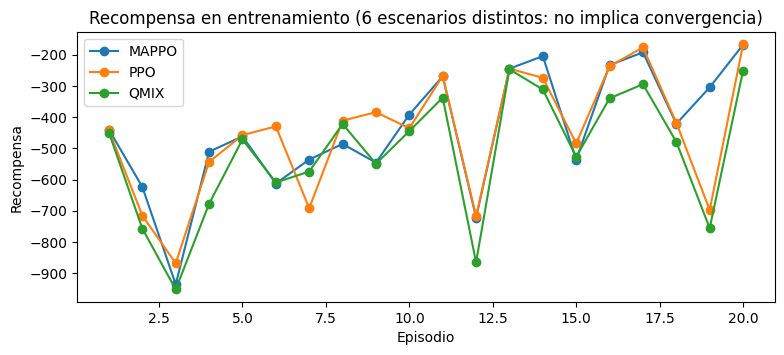

In [ ]:
import random, torch, time
random.seed(SEMILLA);np.random.seed(SEMILLA);torch.manual_seed(SEMILLA)
t0=time.perf_counter()
modelos,curvas=entrenar_tres(tablas,episodios=EPISODIOS_POR_ALGORITMO,semilla=SEMILLA,escenarios_entrenamiento=ENTRENAMIENTO)
print('Episodios por algoritmo:',EPISODIOS_POR_ALGORITMO,'| segundos:',round(time.perf_counter()-t0,1))
display(curvas.groupby('metodo',as_index=False).agg(episodios=('episodio','count'),recompensa_media=('recompensa','mean'),tardanza_media=('tardanza_min','mean'),completos=('completo','sum')).round(2))
assert curvas.completo.all(), 'Entrenamiento con episodios incompletos'
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,3.5))
for metodo,g in curvas.groupby('metodo'):
    ax.plot(g.episodio,g.recompensa,marker='o',label=metodo)
ax.set(xlabel='Episodio',ylabel='Recompensa',title='Recompensa en entrenamiento (6 escenarios distintos: no implica convergencia)')
ax.legend();plt.show()

#### 6.3 · Evaluar todos los métodos en igualdad de condiciones

**¿Qué hace?** Ejecuta FIJA, heurística, PPO, MAPPO y QMIX sobre los mismos escenarios reservados para evaluación.

**¿Qué observarás?** Se obtienen métricas comparables, como tardanza, distancia, esperas y cambios de ruta.

In [ ]:
METODOS=['FIJA','HEURISTICA','PPO','MAPPO','QMIX']
comparaciones=[];logs_politicas={}
for sid in VALIDACION+PRUEBA:
    for metodo in METODOS:
        k,l=evaluar_politica(tablas,sid,modelo=modelos.get(metodo),metodo=metodo,semilla=SEMILLA)
        comparaciones.append(dict(k,particion='VALIDACION' if sid in VALIDACION else 'PRUEBA',metodo=metodo))
        logs_politicas[(sid,metodo)]=l
EVAL=pd.DataFrame(comparaciones)
PR=EVAL.query("particion=='PRUEBA'")
AG=PR.groupby('metodo',as_index=False).agg(entregas=('entregas','sum'),km=('distancia_km','sum'),tardanza_min=('tardanza_min_valida','sum'),espera_min=('espera_min','sum'),replanificaciones=('replanificaciones','sum'),escenarios=('escenario','nunique'))
ref=AG.loc[AG.metodo=="FIJA"].iloc[0]
for c in ['km','tardanza_min','espera_min']:
    AG['diferencia_'+c+'_vs_fija']=AG[c]-ref[c]
display(PR[['escenario','metodo','entregas','tardanza_min_valida','distancia_km','espera_recepcion_cola_min','replanificaciones','finalizado']].round(2))
display(AG.round(2))
assert PR.finalizado.all(), 'Evaluación incompleta'
print('V15: comparación exploratoria; no implica convergencia, requiere múltiples semillas y más episodios.')

/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  ee.loc[dur.notna(),'atencion_obj_min']=dur[dur.notna()].clip(lower=5,upper=360)
/tmp/ipykernel_787/4203815950.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[75. 77. 90. ... 74. 74. 74.]' has dtype incompatible with int64, please explicitly cast to a compatib

,escenario,metodo,entregas,tardanza_min_valida,distancia_km,espera_recepcion_cola_min,replanificaciones,finalizado
10,8141,FIJA,17,5005.00,2699.00,66.0,0,True
11,8141,HEURISTICA,17,4106.00,2717.88,37.8,9,True
12,8141,PPO,17,5031.76,2749.66,7.0,4,True
13,8141,MAPPO,17,5001.66,2706.38,6.0,1,True
14,8141,QMIX,17,8544.49,2772.79,55.6,25,True
15,8142,FIJA,21,10383.08,3069.00,214.0,0,True
16,8142,HEURISTICA,21,8613.47,3095.42,162.0,11,True
17,8142,PPO,21,12989.68,3075.58,350.0,7,True
18,8142,MAPPO,21,11648.08,3083.45,272.0,1,True
19,8142,QMIX,21,18512.95,3127.56,92.8,29,True


,metodo,entregas,km,tardanza_min,espera_min,replanificaciones,escenarios,diferencia_km_vs_fija,diferencia_tardanza_min_vs_fija,diferencia_espera_min_vs_fija
0,FIJA,38,5768.00,15388.08,10136.58,0,2,0.00,0.00,0.00
1,HEURISTICA,38,5813.30,12719.47,10265.36,20,2,45.30,-2668.61,128.78
2,MAPPO,38,5789.82,16649.74,10426.06,2,2,21.82,1261.66,289.48
3,PPO,38,5825.24,18021.44,11785.76,11,2,57.23,2633.36,1649.17
4,QMIX,38,5900.35,27057.44,12705.70,54,2,132.35,11669.36,2569.12


V15: comparación exploratoria; no implica convergencia, requiere múltiples semillas y más episodios.


## 7. Panel de comparación e interpretación

Los gráficos siguientes se calculan desde la **ejecución actual** (`PR`, `AG`, `EVAL`, `curvas` y los registros de los viajes), no desde resultados escritos manualmente. Las diferencias se calculan respecto de **FIJA sobre los mismos escenarios**.

**Lectura:** una menor tardanza no implica necesariamente menor costo. Más cambios de ruta tampoco indican una mejor política. El diagnóstico busca explicar *qué cambió*, *dónde* y *qué queda pendiente*.

#### 7.1 · Resumir los resultados

**¿Qué hace?** Construye una tabla de KPI por método a partir de la ejecución actual.

**¿Qué observarás?** Puedes identificar rápidamente el mejor y el peor resultado de cada indicador.

In [ ]:
# 7.1 Resumen ejecutivo, comparable y con unidades explícitas
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
ORDEN=['FIJA','HEURISTICA','PPO','MAPPO','QMIX']
PANEL=AG.set_index('metodo').reindex(ORDEN).reset_index()
base=PANEL.loc[PANEL.metodo.eq('FIJA')].iloc[0]
PANEL['variacion_tardanza_pct']=(PANEL.tardanza_min/base.tardanza_min-1)*100
PANEL['variacion_km_pct']=(PANEL.km/base.km-1)*100
PANEL['km_por_entrega']=PANEL.km/PANEL.entregas
PANEL['tardanza_min_por_entrega']=PANEL.tardanza_min/PANEL.entregas
print(f'CONJUNTO DE PRUEBA: {len(PR.escenario.unique())} escenarios, {int(base.entregas)} entregas por política, 3 agentes simultáneos por escenario')
print(f'ENTRENAMIENTO: {EPISODIOS_POR_ALGORITMO} episodios por algoritmo de {len(ENTRENAMIENTO)} escenarios posibles')
display(PANEL[['metodo','entregas','tardanza_min','variacion_tardanza_pct','km','variacion_km_pct','espera_min','replanificaciones']].round(2).style.format({'tardanza_min':'{:,.1f}','variacion_tardanza_pct':'{:+.1f}%','km':'{:,.1f}','variacion_km_pct':'{:+.1f}%','espera_min':'{:,.1f}'},na_rep='—'))


CONJUNTO DE PRUEBA: 2 escenarios, 38 entregas por política, 3 agentes simultáneos por escenario
ENTRENAMIENTO: 20 episodios por algoritmo de 30 escenarios posibles


,metodo,entregas,tardanza_min,variacion_tardanza_pct,km,variacion_km_pct,espera_min,replanificaciones
0,FIJA,38,"15,388.1",+0.0%,"5,768.0",+0.0%,"10,136.6",0
1,HEURISTICA,38,"12,719.5",-17.3%,"5,813.3",+0.8%,"10,265.4",20
2,PPO,38,"18,021.4",+17.1%,"5,825.2",+1.0%,"11,785.8",11
3,MAPPO,38,"16,649.7",+8.2%,"5,789.8",+0.4%,"10,426.1",2
4,QMIX,38,"27,057.4",+75.8%,"5,900.4",+2.3%,"12,705.7",54


#### 7.2 · Comparar tardanza y variación frente a FIJA

**¿Qué hace?** Muestra gráficos de tardanza acumulada y de diferencias porcentuales respecto de la política fija.

**¿Qué observarás?** Permite explicar qué métodos mejoran o empeoran y cuánto.

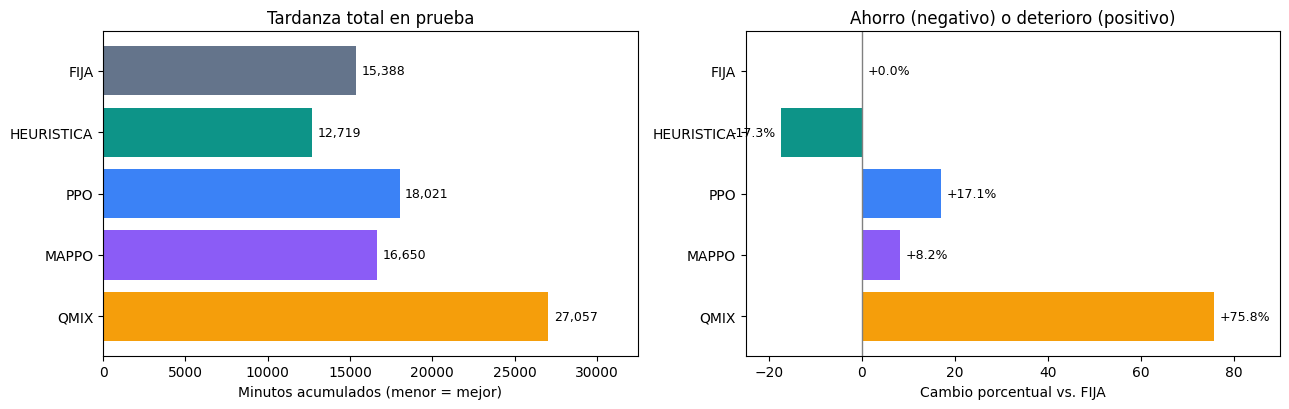

In [ ]:
# 7.2 Gráfico principal: tardanza y diferencia porcentual frente a FIJA
fig,axes=plt.subplots(1,2,figsize=(13,4.2))
y=np.arange(len(PANEL))
colors=['#64748b','#0d9488','#3b82f6','#8b5cf6','#f59e0b']
axes[0].barh(y,PANEL.tardanza_min,color=colors)
axes[0].set_yticks(y,PANEL.metodo);axes[0].invert_yaxis()
axes[0].set_xlabel('Minutos acumulados (menor = mejor)');axes[0].set_title('Tardanza total en prueba')
for i,x in enumerate(PANEL.tardanza_min):axes[0].text(x+max(PANEL.tardanza_min)*.012,i,f'{x:,.0f}',va='center',fontsize=9)
axes[0].set_xlim(0,max(PANEL.tardanza_min)*1.2)
bars=axes[1].barh(y,PANEL.variacion_tardanza_pct,color=colors)
axes[1].set_yticks(y,PANEL.metodo);axes[1].invert_yaxis()
axes[1].axvline(0,color='gray',lw=1);axes[1].set_xlabel('Cambio porcentual vs. FIJA');axes[1].set_title('Ahorro (negativo) o deterioro (positivo)')
for i,x in enumerate(PANEL.variacion_tardanza_pct):
    axes[1].text(x+(1.2 if x>=0 else -1.2),i,f'{x:+.1f}%',ha='left' if x>=0 else 'right',va='center',fontsize=9)
axes[1].set_xlim(min(-25,PANEL.variacion_tardanza_pct.min()-6),max(90,PANEL.variacion_tardanza_pct.max()+12))
plt.tight_layout();plt.show()


#### 7.3 · Comparar escenario por escenario

**¿Qué hace?** Desglosa la tardanza para comprobar si el comportamiento se repite en distintos escenarios.

**¿Qué observarás?** Ayuda a detectar si una ventaja depende de un solo caso.

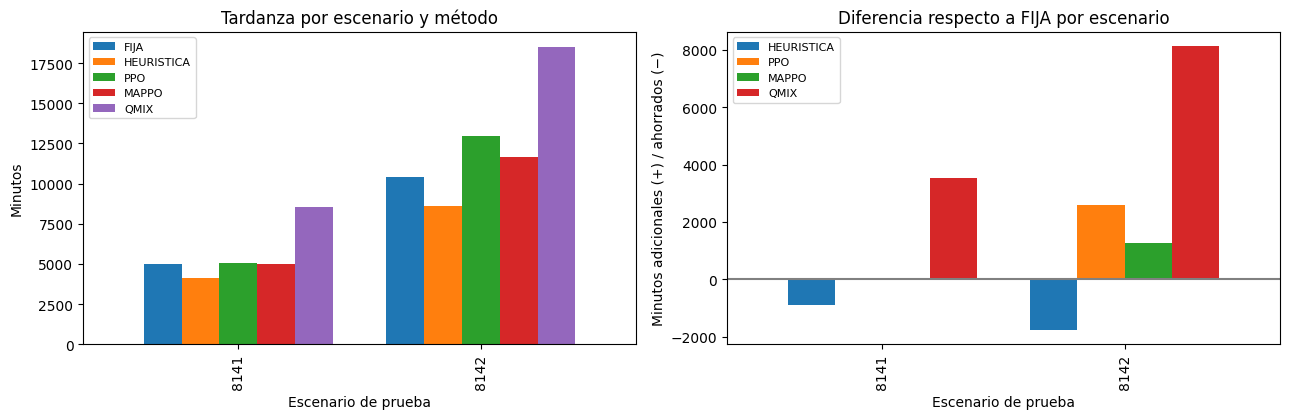

metodo,escenario,HEURISTICA,PPO,MAPPO,QMIX
0,8141,-899.0,26.8,-3.3,3539.5
1,8142,-1769.6,2606.6,1265.0,8129.9


In [ ]:
# 7.3 ¿Las mejoras son generales o provienen de un solo escenario?
DET=PR.pivot_table(index='escenario',columns='metodo',values='tardanza_min_valida',aggfunc='sum').reindex(columns=ORDEN)
DIF=DET.sub(DET['FIJA'],axis=0).drop(columns='FIJA')
fig,axes=plt.subplots(1,2,figsize=(13,4.3))
DET.plot(kind='bar',ax=axes[0],width=.78)
axes[0].set(title='Tardanza por escenario y método',xlabel='Escenario de prueba',ylabel='Minutos',xticklabels=[str(x) for x in DET.index]);axes[0].legend(fontsize=8)
DIF.plot(kind='bar',ax=axes[1],width=.78)
axes[1].axhline(0,color='gray');axes[1].set(title='Diferencia respecto a FIJA por escenario',xlabel='Escenario de prueba',ylabel='Minutos adicionales (+) / ahorrados (−)',xticklabels=[str(x) for x in DIF.index]);axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()
display(DIF.round(1).rename_axis('escenario').reset_index())


#### 7.4 · Relacionar tardanza, distancia y decisiones

**¿Qué hace?** Compara los minutos de retraso con kilómetros, esperas y replanificaciones.

**¿Qué observarás?** Explica por qué recorrer más o cambiar más rutas no siempre es mejor.

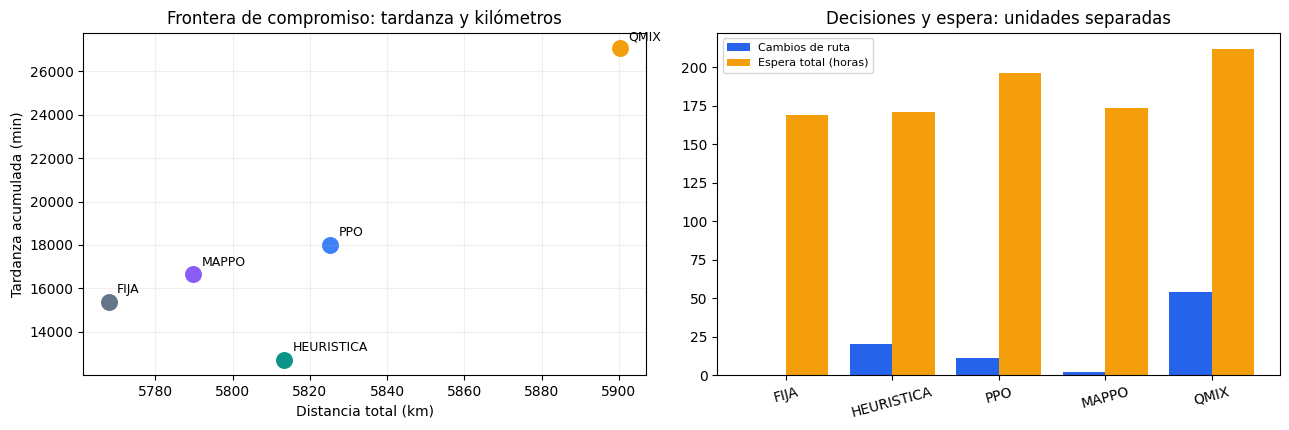

Nota: espera_min incluye esperas acumuladas según la implementación del simulador; no equivale únicamente a cola de recepción.


In [ ]:
# 7.4 Compromiso tardanza–distancia: una ruta más rápida puede costar kilómetros adicionales
fig,axes=plt.subplots(1,2,figsize=(13,4.4))
for j,row in PANEL.iterrows():
    axes[0].scatter(row.km,row.tardanza_min,s=125,color=colors[j]);axes[0].annotate(row.metodo,(row.km,row.tardanza_min),xytext=(6,6),textcoords='offset points',fontsize=9)
axes[0].set(xlabel='Distancia total (km)',ylabel='Tardanza acumulada (min)',title='Frontera de compromiso: tardanza y kilómetros')
axes[0].grid(alpha=.2)
x=np.arange(len(PANEL));w=.40
axes[1].bar(x-w/2,PANEL.replanificaciones,width=w,label='Cambios de ruta',color='#2563eb')
axes[1].bar(x+w/2,PANEL.espera_min/60,width=w,label='Espera total (horas)',color='#f59e0b')
axes[1].set_xticks(x,PANEL.metodo,rotation=15);axes[1].set_title('Decisiones y espera: unidades separadas');axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()
print('Nota: espera_min incluye esperas acumuladas según la implementación del simulador; no equivale únicamente a cola de recepción.')


#### 7.5 · Analizar las colas de recepción

**¿Qué hace?** Separa las esperas asociadas a la atención en los puntos de entrega.

**¿Qué observarás?** Permite identificar cuánto retraso proviene de recursos compartidos.

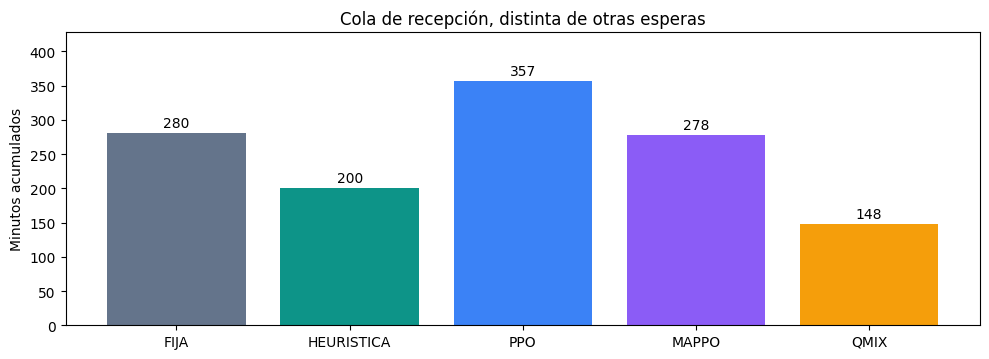

Diagnóstico: si esta variable es pequeña respecto de la espera total, no atribuir toda la tardanza a coordinación de bahías.


In [ ]:
# 7.5 ¿Qué parte de la espera corresponde realmente a recepción?
fig,ax=plt.subplots(figsize=(10,3.7))
colas=PR.groupby('metodo').espera_recepcion_cola_min.sum().reindex(ORDEN).fillna(0)
ax.bar(ORDEN,colas,color=colors)
ax.set(ylabel='Minutos acumulados',title='Cola de recepción, distinta de otras esperas')
for j,v in enumerate(colas):ax.text(j,v+max(1,colas.max()*.025),f'{v:,.0f}',ha='center')
ax.set_ylim(0,max(1,colas.max()*1.2));plt.tight_layout();plt.show()
print('Diagnóstico: si esta variable es pequeña respecto de la espera total, no atribuir toda la tardanza a coordinación de bahías.')


#### 7.6 · Revisar la recompensa RW01–RW06

**¿Qué hace?** Representa las contribuciones registradas de cada componente de recompensa cuando están disponibles.

**¿Qué observarás?** Ayuda a ver qué penalizaciones o incentivos influyen realmente.

,metodo,contrib_RW01,contrib_RW02,contrib_RW03,contrib_RW04,contrib_RW05,contrib_RW06
0,FIJA,57.0,-144.20,-543.65,-641.17,-4.67,0.0
1,HEURISTICA,57.0,-145.33,-539.55,-529.98,-3.33,0.0
2,PPO,57.0,-145.63,-575.92,-750.89,-5.95,0.0
3,MAPPO,57.0,-144.75,-550.10,-693.74,-4.63,0.0
4,QMIX,57.0,-147.51,-675.78,-1127.39,-2.47,0.0


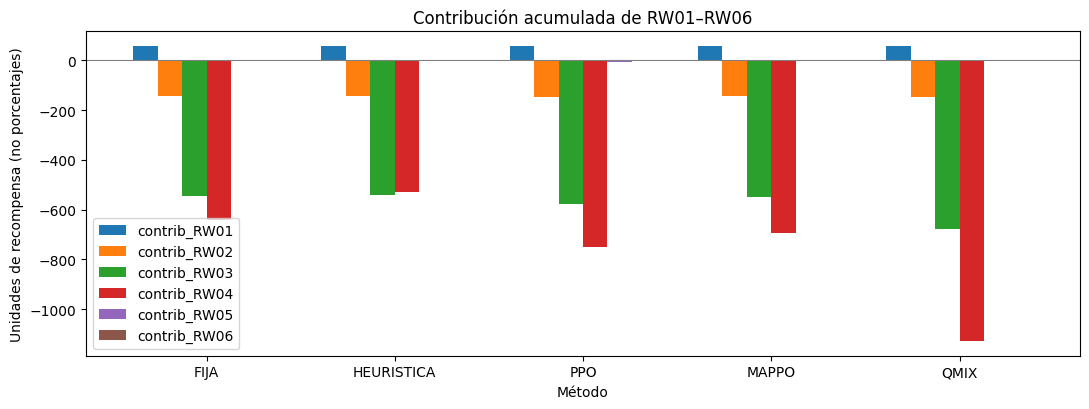

Los pesos nominales 15/25/15/25/10/10 no implican igual proporción en los valores realizados: revisar escalas.


In [ ]:
# 7.6 Distribución de contribuciones reales a la recompensa RW01–RW06, si están presentes
rwcols=[f'contrib_RW{i:02d}' for i in range(1,7)]
presentes=[c for c in rwcols if c in PR.columns]
if len(presentes)==6:
    RW=PR.groupby('metodo')[presentes].sum().reindex(ORDEN)
    display(RW.round(2).rename_axis('metodo').reset_index())
    ax=RW.plot(kind='bar',figsize=(11,4.2),width=.78)
    ax.set(title='Contribución acumulada de RW01–RW06',ylabel='Unidades de recompensa (no porcentajes)',xlabel='Método')
    ax.axhline(0,color='gray',lw=.8);plt.xticks(rotation=0);plt.tight_layout();plt.show()
    print('Los pesos nominales 15/25/15/25/10/10 no implican igual proporción en los valores realizados: revisar escalas.')
else:
    print('La ejecución no expone los seis componentes individualizados. Faltantes:', sorted(set(rwcols)-set(presentes)))


#### 7.7 · Auditar alternativas y acciones

**¿Qué hace?** Contrasta la cobertura de A03 con las acciones y eventos registrados en los viajes.

**¿Qué observarás?** Indica si el entorno ofrece oportunidades y si las políticas las están aprovechando.

Cobertura potencial de A03: 1344/1854 tramos planificados (72.5%)
Alternativas catalogadas: 225; este valor es potencial: la máscara y el límite de conducción reducen acciones factibles.


tipo_evento,DESCANSO,ESPERA_DECIDIDA
metodo,,
FIJA,47,0
HEURISTICA,44,0
PPO,41,23
MAPPO,47,37
QMIX,108,49


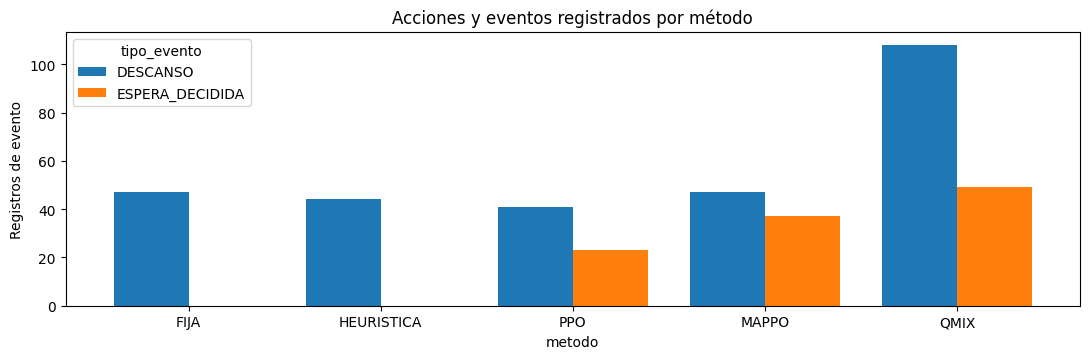

In [ ]:
# 7.7 Evidencia de espacio de decisión: cobertura A03 y trazas de eventos
A=tablas['EXP30_ALT_MAP']
P=tablas['plan_ruta_tramo']
altset=set(pd.to_numeric(A.id_tramo_origen,errors='coerce').dropna().astype(int))
planids=set(pd.to_numeric(tablas['plan_ruta'].loc[tablas['plan_ruta'].id_viaje.isin(tablas['escenario_viaje'].loc[tablas['escenario_viaje'].id_escenario.isin(V14_ESC.id_escenario),'id_viaje']),'id_plan'],errors='coerce').dropna().astype(int))
planes=P[P.id_plan.isin(planids)]
con_alt=planes.id_tramo.isin(altset)
print(f'Cobertura potencial de A03: {int(con_alt.sum())}/{len(planes)} tramos planificados ({con_alt.mean():.1%})')
print(f'Alternativas catalogadas: {len(A)}; este valor es potencial: la máscara y el límite de conducción reducen acciones factibles.')
trazas=[]
for (sid,m),df in logs_politicas.items():
    if sid not in PR.escenario.values or df.empty:continue
    frec=df.tipo.astype(str).value_counts()
    for evento,n in frec.items():trazas.append({'escenario':sid,'metodo':m,'tipo_evento':evento,'registros':int(n)})
TRAZAS=pd.DataFrame(trazas)
if not TRAZAS.empty:
    eventcount=TRAZAS.pivot_table(index='metodo',columns='tipo_evento',values='registros',aggfunc='sum',fill_value=0).reindex(ORDEN).fillna(0)
    importantes=[x for x in eventcount.columns if any(k in x.upper() for k in ('DESV','REORD','ESPERA_DECIDIDA','DESCANSO','COLA'))]
    display(eventcount[importantes] if importantes else eventcount.iloc[:,:12])
    if importantes:
        ax=eventcount[importantes].plot(kind='bar',figsize=(11,3.7),width=.78)
        ax.set(title='Acciones y eventos registrados por método',ylabel='Registros de evento');plt.xticks(rotation=0);plt.tight_layout();plt.show()
else:print('Sin trazas accesibles: revisar logs_politicas')


#### 7.8 · Generar el diagnóstico del piloto

**¿Qué hace?** Resume resultados, limitaciones y tareas técnicas que se desprenden de los indicadores.

**¿Qué observarás?** Prepara una explicación de qué falta corregir antes de afirmar que MARL mejora a FIJA.

In [ ]:
# 7.8 Diagnóstico calculado y tareas siguientes (no confundir inferencia con causalidad probada)
heur=PANEL.set_index('metodo').loc['HEURISTICA'];fija=PANEL.set_index('metodo').loc['FIJA']
mejoran=PANEL[(PANEL.metodo.isin(['PPO','MAPPO','QMIX'])) & (PANEL.tardanza_min<fija.tardanza_min)]
resumen=[
    ('Alternativas viables',f'{len(A)} corredores; {con_alt.mean():.1%} de tramos planificados cubiertos potencialmente','Verificar factibilidad de ruta completa, geometría y restricciones para camión'),
    ('Señal del entorno',f'Heurística vs FIJA: {(1-heur.tardanza_min/fija.tardanza_min)*100:.1f}% menos tardanza, {heur.km-fija.km:+.1f} km','Comparar rutas con igual información, riesgo, costo y tiempo'),
    ('Aprendizaje',f'{EPISODIOS_POR_ALGORITMO} episodios por algoritmo; {len(ENTRENAMIENTO)} escenarios de entrenamiento disponibles','Más episodios y semillas; ver curvas en escenarios repetidos de validación'),
    ('MARL vs FIJA',f'{len(mejoran)} de 3 algoritmos con menor tardanza en esta prueba','Revisar observación/ETA, máscara A03, escala RW y crédito temporal'),
    ('Cooperación','3 vehículos por escenario, reloj compartido','Probar conflictos medibles de recursos y ablasión sin información compartida'),
    ('QMIX','Implementación experimental con decisiones asíncronas','Revisar representación conjunta y transiciones antes de comparar'),
    ('Validez externa','Rutas alternativas y bahías son supuestos experimentales','Validar red vial con GeoJSON y capacidad/horario de recepción'),
]
display(pd.DataFrame(resumen,columns=['Componente','Evidencia del piloto','Pendiente priorizado']))
print('INTERPRETACIÓN: si la heurística mejora y MARL no, el simulador permite algunas decisiones útiles; no demuestra aún que las redes hayan aprendido a aprovecharlas.')
print('No se puede atribuir causalidad a una sola variable con solo 2 escenarios y una semilla.')


,Componente,Evidencia del piloto,Pendiente priorizado
0,Alternativas viables,225 corredores; 72.5% de tramos planificados c...,"Verificar factibilidad de ruta completa, geome..."
1,Señal del entorno,"Heurística vs FIJA: 17.3% menos tardanza, +45....","Comparar rutas con igual información, riesgo, ..."
2,Aprendizaje,20 episodios por algoritmo; 30 escenarios de e...,Más episodios y semillas; ver curvas en escena...
3,MARL vs FIJA,0 de 3 algoritmos con menor tardanza en esta p...,"Revisar observación/ETA, máscara A03, escala R..."
4,Cooperación,"3 vehículos por escenario, reloj compartido",Probar conflictos medibles de recursos y ablas...
5,QMIX,Implementación experimental con decisiones así...,Revisar representación conjunta y transiciones...
6,Validez externa,Rutas alternativas y bahías son supuestos expe...,Validar red vial con GeoJSON y capacidad/horar...


INTERPRETACIÓN: si la heurística mejora y MARL no, el simulador permite algunas decisiones útiles; no demuestra aún que las redes hayan aprendido a aprovecharlas.
No se puede atribuir causalidad a una sola variable con solo 2 escenarios y una semilla.


## 8. Conclusiones para la presentación

**Hallazgo 1 — Existe margen operativo:** la heurística dinámica puede elegir rutas alternativas y reducir tardanza frente a FIJA, normalmente con una compensación en distancia. Esto **no es todavía un resultado de aprendizaje por refuerzo**.

**Hallazgo 2 — Hay brecha de aprendizaje:** PPO, MAPPO y QMIX pueden tomar más decisiones sin obtener mejores KPI. Debe revisarse la representación de ETA/costo por alternativa, la factibilidad de la ruta completa y las escalas de recompensa.

**Hallazgo 3 — La coordinación necesita una prueba específica:** tres camiones en el mismo episodio no garantizan conflictos entre ellos. Se necesitan escenarios de recursos compartidos con interacciones causales, sin alterar los hechos históricos.

**Hallazgo 4 — La evaluación es exploratoria:** seis episodios por método y dos escenarios de prueba son insuficientes para generalizar. QMIX requiere además una revisión de su implementación asíncrona.

**Próxima iteración sugerida:** auditoría de A03 y observaciones → comparación justa con heurística dinámica → entrenamiento repetido con múltiples semillas → análisis de coordinación y ablasiones → validación geográfica. No se debe fabricar una ventaja para MARL.

#### 8.1 · Guardar tablas para la presentación

**¿Qué hace?** Exporta los datos comparativos y las tablas de interpretación.

**¿Qué observarás?** Se generan archivos CSV que puedes abrir para revisar las diferencias.

In [ ]:
# 8.1 Exportaciones de los gráficos y datos de interpretación
from pathlib import Path
OUT_ANALISIS=Path('EYM_V15_RESULTADOS');OUT_ANALISIS.mkdir(exist_ok=True)
PANEL.to_csv(OUT_ANALISIS/'panel_comparativo_explicativo.csv',index=False,encoding='utf-8-sig')
DIF.to_csv(OUT_ANALISIS/'diferencias_por_escenario.csv',encoding='utf-8-sig')
if not TRAZAS.empty:TRAZAS.to_csv(OUT_ANALISIS/'frecuencias_eventos.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(resumen,columns=['componente','evidencia','pendiente']).to_csv(OUT_ANALISIS/'tareas_pendientes.csv',index=False,encoding='utf-8-sig')
print('Archivos de análisis exportados:',OUT_ANALISIS.resolve())


Archivos de análisis exportados: /content/EYM_V15_RESULTADOS


#### 8.2 · Guardar registros finales de la simulación

**¿Qué hace?** Exporta resultados de entrenamiento, evaluación y validación de escenarios.

**¿Qué observarás?** Queda disponible la evidencia cuantitativa del piloto.

In [ ]:
from pathlib import Path
O=Path('EYM_V15_RESULTADOS');O.mkdir(exist_ok=True)
VALIDACION_CARGA.to_csv(O/'validacion_carga_50_escenarios.csv',index=False,encoding='utf-8-sig')
curvas.to_csv(O/'entrenamiento.csv',index=False,encoding='utf-8-sig')
PR.to_csv(O/'comparacion_por_escenario.csv',index=False,encoding='utf-8-sig')
AG.to_csv(O/'resumen_politicas.csv',index=False,encoding='utf-8-sig')
AUDITORIA_V14.to_csv(O/'auditoria_escenarios.csv',index=False,encoding='utf-8-sig')
print('Resultados:',O,'| El Excel V7 sigue intacto.')

AUDITORIA_RUTAS_V15.to_csv(O/'auditoria_alternativas.csv',index=False,encoding='utf-8-sig')


Resultados: EYM_V15_RESULTADOS | El Excel V7 sigue intacto.
